# PK-coupled Boolean simulation — CLL ibrutinib model v6 (CLL-refined)
## AUCell-grounded initialisation

This notebook integrates three data layers into a unified simulation pipeline:

1. **Pharmacokinetic (PK) layer** — monthly ibrutinib trough concentrations
   converted to BTK inhibition rates via the Hill equation
2. **Transcriptomic layer** — pySCENIC AUCell regulon activity scores at M0,
   M3, and M27 used to initialise TF node states in the Boolean model
3. **Clonal evolution layer** — PLCG2_mutant probability modelled as a logistic
   function of cumulative ibrutinib exposure (AUC-driven)

AUCell initialisation is applied from the very first simulation — all three
condition-specific starting states (M0, M3, M27) are grounded in the
transcriptomic data. Pharmacological locks (BTK, BCL2 family, cytokines) always
take priority over AUCell-derived states.

## Notebook structure

| Section | Description |
|---|---|
| 0 | Imports, file paths, all parameters |
| 1 | PK data loading and monthly concentration extraction |
| 2 | PK→PD conversion: Hill equation, BTK rate_up |
| 3 | AUCell loading and threshold analysis |
| 4 | PLCG2_mutant model and simulation helpers (AUCell-aware) |
| 5 | Reference attractor simulations (M0, M3, M27 from AUCell) |
| 6 | Main PK-coupled simulation — AUCell M0 start |
| 7 | PK-coupled trajectories from M3 and M27 AUCell starts |
| 8 | Trajectory comparison: M0 vs M3 vs M27 starting states |
| 9 | Results summary, trajectory figure, replicate heatmap |
| 10 | Sensitivity: IC50 uncertainty |
| 11 | Sensitivity: AUC₅₀ fraction |
| 12 | Transition detection |
| 13 | Supplementary shared setup (v5 helpers, screen nodes) |
| 14 | S1 — Single-node screen at M27 |
| 15 | S1b — Single-node screen at M3 |
| 16 | S2 — Cytokine rescue at M27 |
| 17 | S3 — Bliss synergy screen (M3 background) |
| 18 | S3b — Bliss synergy screen (M0 background) |
| 19 | S4 — Basin of attraction mapping M3 → M27 |
| 20 | S5 — BTK dose-response |

## Required files
- `leukemia_hgnc_v4CLL_v6.bnd`
- `init_v6_base.cfg`
- `pk_data.xlsx`
- `aucell_binary_consensus.csv` (binary 0/1 per regulon per timepoint, from R AUCell binarisation)

---
## 0. Imports and configuration

All file paths and numerical parameters are centralised here.

In [58]:
import maboss
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import re as _re
import os
import warnings
from itertools import combinations
from scipy import stats as _stats
from scipy.signal import find_peaks as _find_peaks
from scipy.integrate import cumulative_trapezoid
warnings.filterwarnings('ignore')

os.makedirs('pk_coupled_results', exist_ok=True)
OUTPUT_DIR = 'pk_coupled_results'

# ── Model files (v6: CLL-refined, 37 nodes) ───────────────────────────────────
BND_FILE = 'leukemia_hgnc_CLL_reduced37nodes.bnd'
CFG_BASE = 'init_base_reduced37nodes.cfg'

OUTPUT_NODES      = ['Apoptosis', 'Proliferation', 'Growth_Arrest', 'Resistance']
# v6 RESISTANCE_INPUTS: SYK still in model but feeds PI3K not Resistance directly
# Remove nodes not present in v6 (VEGFA,EPO,GH1,Wnt,KDR,SRC,EPOR,GHR,CRKL,CBL,
#                                   SMAD,FZD,AXIN2,CTNNB1,TCF removed)
RESISTANCE_INPUTS = ['PLCG2', 'BTK', 'MTOR', 'BCL2L1', 'NFKB1']

# ── PK parameters ─────────────────────────────────────────────────────────────
PK_FILE    = 'ID6_concentrations_final_updated.xlsx'
IC50_NG_ML = 1.0
HILL_N     = 1.0

# ── AUCell parameters ─────────────────────────────────────────────────────────
AUCELL_FILE      = 'aucell_binary_consensus.csv'  # binary 0/1 per TF per timepoint
AUCELL_THRESHOLD = 0.5   # threshold on fraction-of-cells (binary consensus)

# TF → Boolean node mapping (v6 node names)
# Removed vs v5: TCF7, TCF4 (TCF node removed), FOXO1, FOXO3 (FOXO still present)
# Note: FOXO IS still in v6 — keep FOXO1/FOXO3 mapping
# Note: TCF removed from v6 — drop TCF7/TCF4
TF_TO_NODE = {
    'MYC':    'MYC',
    'JUN':    'JUN',
    'JUNB':   'JUNB',
    'STAT5A': 'STAT5',
    'STAT5B': 'STAT5',
    'NFKB1':  'NFKB1',
    'RELA':   'NFKB1',
    'CEBPA':  'CEBPA',
    'FOXO1':  'FOXO',
    'FOXO3':  'FOXO',
}

# AUCell cannot override these nodes — mechanistic reasons only:
#   BTK          — activity set by PK (Hill equation), not transcription
#   PLCG2_mutant — somatic mutation, not a transcriptional state
#   PLCG2        — purely downstream of BTK/PLCG2_mutant; no AUCell signal
# All other intersecting nodes are data-driven from AUCell binary consensus.
AUCELL_LOCKED = {'BTK', 'PLCG2_mutant', 'PLCG2'}

# ── PLCG2_mutant model ────────────────────────────────────────────────────────
AUC_50_FRACTION = 0.70

# ── Simulation parameters ─────────────────────────────────────────────────────
N_REPS       = 50
SAMPLE_COUNT = 50000
MAX_TIME     = 20
TIME_TICK    = 0.1
N_THREADS    = 4

# Nodes not inherited from previous month (set by condition logic each step)
# EPO/GH1 removed from v6 — only IL3 remains as the cytokine node
CHAINING_LOCKED = {'PLCG2_mutant', 'IL3'}

print('Configuration loaded - v6 CLL-refined model (37 nodes)')
print(f'BND: {BND_FILE}  |  CFG: {CFG_BASE}')
print(f'IC50: {IC50_NG_ML} ng/mL  |  AUC_50_fraction: {AUC_50_FRACTION}')
print(f'N_REPS: {N_REPS}  |  SAMPLE_COUNT: {SAMPLE_COUNT}')
print(f'AUCELL_LOCKED: {sorted(AUCELL_LOCKED)}')

Configuration loaded - v6 CLL-refined model (37 nodes)
BND: leukemia_hgnc_CLL_reduced37nodes.bnd  |  CFG: init_base_reduced37nodes.cfg
IC50: 1.0 ng/mL  |  AUC_50_fraction: 0.7
N_REPS: 50  |  SAMPLE_COUNT: 50000
AUCELL_LOCKED: ['BTK', 'PLCG2', 'PLCG2_mutant']


---
## 1. PK data loading and monthly concentration extraction

**Question:** What is the monthly ibrutinib trough and cumulative exposure
experienced by this patient over the 27-month treatment course?

The trough (mean of bottom 10th percentile of hourly `Cp_IBRU_pred` per month)
is the pharmacologically relevant quantity for a covalent inhibitor — residual
unoccupied BTK accumulates during trough periods. Cumulative AUC drives the
PLCG2_mutant clonal expansion model in Section 4.

In [59]:
pk_raw = pd.read_excel(PK_FILE)
print(f'Loaded: {pk_raw.shape[0]} rows × {pk_raw.shape[1]} columns')

pk_df = pk_raw.dropna(subset=['Cp_IBRU_pred', 'time_abs_mo']).copy()
pk_df = pk_df[pk_df['Cp_IBRU_pred'] >= 0].copy()
pk_df['month'] = pk_df['time_abs_mo'].apply(lambda x: int(np.floor(x)))

def monthly_trough(group):
    p10 = np.percentile(group['Cp_IBRU_pred'], 10)
    return group.loc[group['Cp_IBRU_pred'] <= p10, 'Cp_IBRU_pred'].mean()

monthly_stats = pk_df.groupby('month').apply(
    lambda g: pd.Series({
        'mean_conc':   g['Cp_IBRU_pred'].mean(),
        'trough_conc': monthly_trough(g),
        'peak_conc':   g['Cp_IBRU_pred'].quantile(0.90),
        'n_hours':     len(g),
    })
).reset_index()

if 0 not in monthly_stats['month'].values:
    monthly_stats = pd.concat([
        pd.DataFrame([{'month':0,'mean_conc':0,'trough_conc':0,
                       'peak_conc':0,'n_hours':0}]),
        monthly_stats
    ], ignore_index=True)
monthly_stats = monthly_stats.sort_values('month').reset_index(drop=True)

pk_sorted = pk_df.sort_values('time_abs_d').reset_index(drop=True)
pk_sorted['cum_auc'] = cumulative_trapezoid(
    pk_sorted['Cp_IBRU_pred'].values, pk_sorted['time_abs_d'].values, initial=0)
monthly_cum_auc = (pk_sorted.groupby('month')['cum_auc'].max()
                   .reset_index().rename(columns={'cum_auc':'cum_auc_end_of_month'}))
monthly_stats = monthly_stats.merge(monthly_cum_auc, on='month', how='left')
monthly_stats['cum_auc_end_of_month'] = monthly_stats['cum_auc_end_of_month'].fillna(0)

monthly_stats.to_csv(f'{OUTPUT_DIR}/monthly_pk_concentrations.csv', index=False)
print(f'Month range: {monthly_stats["month"].min()} – {monthly_stats["month"].max()}')
print(monthly_stats[['month','trough_conc','cum_auc_end_of_month']].to_string(index=False))

Loaded: 19755 rows × 9 columns
Month range: 0 – 27
 month  trough_conc  cum_auc_end_of_month
     0     1.058554            281.844026
     1     0.744479            512.189129
     2     1.861723            877.245129
     3     1.956768           1236.567254
     4     1.799923           1587.410146
     5     1.804147           1935.383842
     6     1.793467           2281.226349
     7     1.802574           2633.957397
     8     1.800267           2978.985577
     9     1.794813           3332.279662
    10     1.802574           3677.771588
    11     1.793467           4029.982068
    12     1.802574           4376.508438
    13     1.793467           4726.037750
    14     1.802574           5075.167891
    15     1.793467           5419.946447
    16     1.799987           5773.679594
    17     1.802574           6118.827879
    18     1.793467           6471.855710
    19     1.802574           6817.599402
    20     1.793467           7169.178279
    21     1.802574      

---
## 2. PK → PD conversion: Hill equation and BTK rate_up

**Question:** How does the monthly trough concentration translate into a
Boolean model BTK activation rate?

$$\text{BTK\_rate\_up} = 1 - \frac{C^n}{\text{IC50}^n + C^n}$$

With IC50 = 1.0 ng/mL and the observed steady-state trough of ~1.8 ng/mL,
this gives BTK_rate_up ≈ 0.36 — a constant partial inhibition that does not
change between M3 and M27. The M3→M27 phenotypic transition is therefore
driven by PLCG2_mutant clonal expansion (Section 4), not by changing PK.

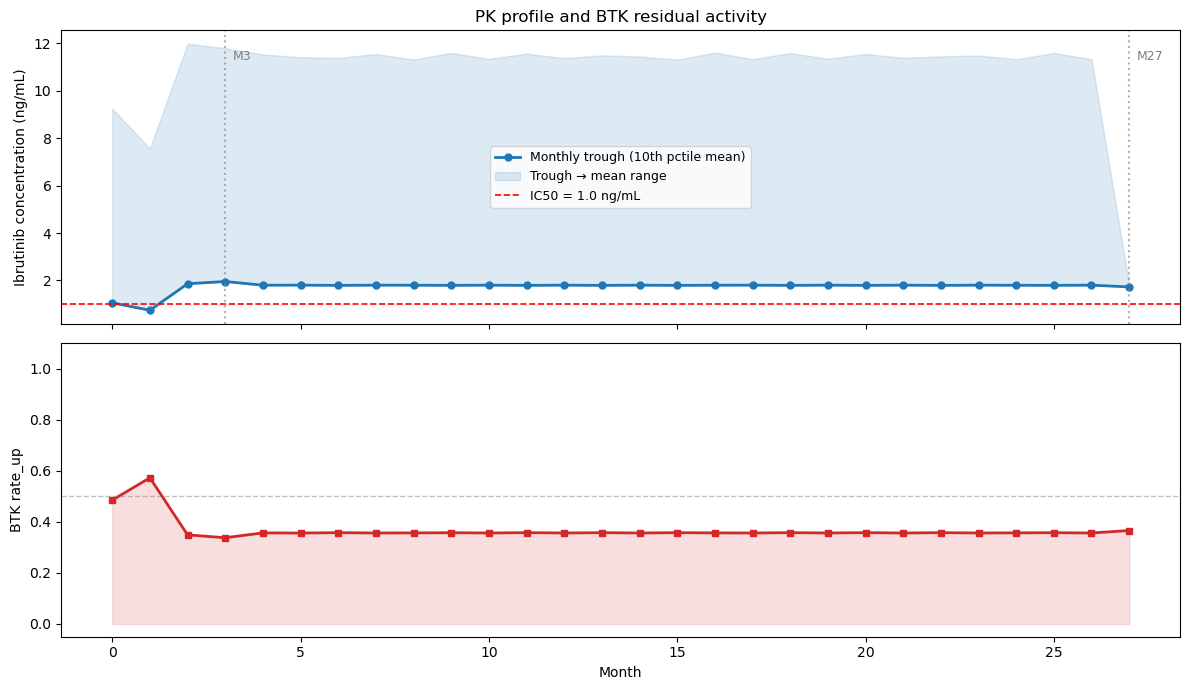

In [60]:
def conc_to_inhibition(C, IC50=IC50_NG_ML, n=HILL_N):
    if C <= 0: return 0.0
    return (C**n) / (IC50**n + C**n)

def conc_to_btk_rate(C, IC50=IC50_NG_ML, n=HILL_N):
    return round(1.0 - conc_to_inhibition(C, IC50, n), 6)

monthly_stats['inhibition']  = monthly_stats['trough_conc'].apply(conc_to_inhibition)
monthly_stats['btk_rate_up'] = monthly_stats['trough_conc'].apply(conc_to_btk_rate)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
months = monthly_stats['month'].values
ax1.plot(months, monthly_stats['trough_conc'], 'o-', color='#1f77b4',
         linewidth=2, markersize=5, label='Monthly trough (10th pctile mean)')
ax1.fill_between(months, monthly_stats['trough_conc'], monthly_stats['mean_conc'],
                 alpha=0.15, color='#1f77b4', label='Trough → mean range')
ax1.axhline(IC50_NG_ML, color='red', linestyle='--', linewidth=1.2,
            label=f'IC50 = {IC50_NG_ML} ng/mL')
for xv, lbl in [(3,'M3'),(27,'M27')]:
    ax1.axvline(xv, color='gray', linestyle=':', alpha=0.6)
    ax1.text(xv+0.2, ax1.get_ylim()[1]*0.9, lbl, fontsize=9, color='gray')
ax1.set_ylabel('Ibrutinib concentration (ng/mL)', fontsize=10)
ax1.legend(fontsize=9)
ax1.set_title('PK profile and BTK residual activity', fontsize=12)
ax2.plot(months, monthly_stats['btk_rate_up'], 's-', color='#d62728',
         linewidth=2, markersize=5)
ax2.fill_between(months, 0, monthly_stats['btk_rate_up'], alpha=0.15, color='#d62728')
ax2.axhline(0.5, color='gray', linestyle='--', linewidth=1, alpha=0.5)
ax2.set_ylim(-0.05, 1.1)
ax2.set_ylabel('BTK rate_up', fontsize=10); ax2.set_xlabel('Month', fontsize=10)
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/pk_btk_rate_profile.pdf', dpi=300, bbox_inches='tight')
plt.show()

---
## 3. AUCell loading and threshold analysis

**Question:** What binary TF activity states does the transcriptomic data
support at M0, M3, and M27, and what threshold best separates active from
inactive regulons?

AUCell scores quantify enrichment of each TF's regulon gene set in the top-
ranked genes of each cell. Per-condition mean scores are binarised at a
threshold determined by four complementary analyses:

1. Score distribution visualisation (KDE per condition)
2. Bimodality analysis — Sarle's BC > 0.555 indicates bimodal distribution;
   valley between modes is the natural binarisation point
3. Condition discriminability — threshold that maximises the number of TF
   nodes with different states between M0/M3/M27
4. Attractor stability — threshold must preserve correct M0 attractor

The selected threshold is stored in `AUCELL_THRESHOLD` and used in all
downstream simulations. It can be overridden manually after reviewing the plots.

**R export code** (run in your Seurat session before this notebook):
```r
agg <- sapply(c("M0","M3","M27"), function(tp) {
  cells <- colnames(seurat)[seurat$timepoint == tp]
  rowMeans(seurat@assays$AUCell@data[, cells])
})
write.csv(agg, "aucell_scores.csv")
```

In [61]:
# ── Load AUCell scores ────────────────────────────────────────────────────────
try:
    aucell_df = pd.read_csv(AUCELL_FILE, index_col=0)
    aucell_df.columns = [c.strip() for c in aucell_df.columns]
    aucell_df = aucell_df[[c for c in ['M0','M3','M27'] if c in aucell_df.columns]]
    print(f'Loaded: {len(aucell_df)} TFs × {len(aucell_df.columns)} conditions')
    print(f'Score range: {aucell_df.values.min():.4f} – {aucell_df.values.max():.4f}')
    AUCELL_AVAILABLE = True
except FileNotFoundError:
    print(f'WARNING: {AUCELL_FILE} not found — using rule-based defaults only')
    AUCELL_AVAILABLE = False

COND_COLORS = {'M0':'#2ca02c','M3':'#1f77b4','M27':'#d62728'}

Loaded: 568 TFs × 3 conditions
Score range: 0.0000 – 1.0000


In [62]:
# ── Binarise AUCell scores and build per-condition TF states ─────────────────
# This cell computes aucell_istates — used by ALL downstream simulations.

def compute_aucell_istates(threshold=None):
    """
    Binary TF states per condition from AUCell scores.
    When multiple TFs map to the same node, the maximum score is used
    (OR logic — a node is active if any of its mapped TFs is active).
    """
    if threshold is None:
        threshold = AUCELL_THRESHOLD
    istates = {'M0':{}, 'M3':{}, 'M27':{}}
    if not AUCELL_AVAILABLE:
        return istates
    for tf, node in TF_TO_NODE.items():
        for cond in ['M0','M3','M27']:
            if tf in aucell_df.index and cond in aucell_df.columns:
                score   = float(aucell_df.loc[tf, cond])
                current = istates[cond].get(node, 0)
                istates[cond][node] = max(current, int(float(score)))  # binary consensus: direct read
    return istates

aucell_istates = compute_aucell_istates()

print(f'AUCell threshold: {AUCELL_THRESHOLD}')
print(f'\n{"Node":<12}  {"M0":>5}  {"M3":>5}  {"M27":>5}')
print('  ' + '-'*30)
for node in sorted(set(TF_TO_NODE.values())):
    m0  = aucell_istates['M0'].get(node, 'N/A')
    m3  = aucell_istates['M3'].get(node, 'N/A')
    m27 = aucell_istates['M27'].get(node, 'N/A')
    print(f'{node:<12}  {str(m0):>5}  {str(m3):>5}  {str(m27):>5}')

AUCell threshold: 0.5

Node             M0     M3    M27
  ------------------------------
CEBPA             0      0      0
FOXO              0      0      0
JUN               0      0      1
JUNB              0      0      1
MYC               1      0      1
NFKB1             0      0      0
STAT5             0      0      0


---
## 4. PLCG2_mutant model and simulation helpers

**Question:** How does cumulative ibrutinib exposure drive PLCG2_mutant clonal
expansion, and how are AUCell-derived TF states applied to Boolean simulations?

Three simulation builders are defined here:

- `build_sim_static(condition)` — fixed condition, pharmacological locks only,
  no AUCell, no PK coupling. Used for attractor verification.
- `build_sim_aucell(condition)` — fixed condition with AUCell TF initialisation
  on top of pharmacological locks. Used for S1–S5 supplementary analyses.
- `build_pk_sim(month, btk_rate_up, prev_state)` — PK-coupled monthly step
  with AUCell-derived M0 initial state at month 0, then state chaining.

In all builders, `AUCELL_LOCKED` nodes are never overridden by AUCell — drug
mechanism always takes priority over transcriptomic state.

In [50]:
# ── PLCG2_mutant logistic expansion ──────────────────────────────────────────
total_auc_M27 = monthly_stats['cum_auc_end_of_month'].max()
AUC_50 = total_auc_M27 * AUC_50_FRACTION
K_AUC  = 8.0 / total_auc_M27

print(f'Total cumulative AUC at M27: {total_auc_M27:.1f} ng/mL·day')
print(f'AUC_50 = {AUC_50:.1f} (fraction={AUC_50_FRACTION})  k={K_AUC:.6f}')

def plcg2_mut_prob(month):
    """P(PLCG2_mutant) from cumulative AUC at given month."""
    row = monthly_stats[monthly_stats['month'] == month]
    if row.empty: return 0.0
    cum = float(row['cum_auc_end_of_month'].values[0])
    if cum <= 0: return 0.0
    return 1.0 / (1.0 + np.exp(-K_AUC * (cum - AUC_50)))

cross = next((m for m in monthly_stats['month'] if plcg2_mut_prob(m) >= 0.5), None)
print(f'P=0.5 crossing at: M{int(cross) if cross else "never"}')

Total cumulative AUC at M27: 9258.9 ng/mL·day
AUC_50 = 6481.2 (fraction=0.7)  k=0.000864
P=0.5 crossing at: M19


In [63]:
# ── Simulation builder: static (pharmacological locks only) ──────────────────
def build_sim_static(condition):
    """
    Static simulation with pharmacological locks for the given condition.
    BTK is set via the Hill equation from the mean trough concentration
    at each clinical period — never locked OFF as a binary approximation.

    M0:  no drug → BTK rate_up = 1.0 (fully active)
    M3:  ibrutinib at steady state → BTK rate_up from mean M3 trough (~0.35)
    M27: same PK exposure as M3 (flat profile) → same BTK rate_up (~0.35)
          but PLCG2_mutant ON and BCL2/MCL1 ON (acquired resistance mechanisms)
    """
    sim = maboss.load(BND_FILE, CFG_BASE)
    maboss.set_output(sim, OUTPUT_NODES + RESISTANCE_INPUTS)
    sim.mutate('PLCG2_mutant', 'OFF')

    def get_btk_rate(cond):
        """Mean trough-derived BTK rate_up for a clinical condition."""
        MONTHS = {'M0': [0], 'M3': [2, 3, 4], 'M27': [25, 26, 27]}
        rows = monthly_stats[monthly_stats['month'].isin(MONTHS[cond])]
        if rows.empty or cond == 'M0':
            return 1.0
        return conc_to_btk_rate(rows['trough_conc'].mean())

    if condition == 'M0':
        sim.network['BTK'].set_rate('1.0', '1.0')   # no drug

    elif condition == 'M3':
        btk_rate = get_btk_rate('M3')
        sim.network['BTK'].set_rate(str(round(btk_rate, 6)), '1.0')
        #sim.mutate('IL3', 'OFF')
        # PLCG2: not locked — determined by BTK rate_up and PLCG2_mutant=OFF
        # BCL2 family: not locked — AUCell M3 states applied in build_sim_aucell
        # AKT, PI3K, MYC: not locked — determined by network dynamics

    elif condition == 'M27':
        btk_rate = get_btk_rate('M27')
        sim.network['BTK'].set_rate(str(round(btk_rate, 6)), '1.0')
        sim.mutate('PLCG2_mutant', 'ON')
        sim.mutate('BCL2',         'ON')
        sim.mutate('MCL1',         'ON')

    sim.param['max_time']     = MAX_TIME
    sim.param['time_tick']    = TIME_TICK
    sim.param['sample_count'] = SAMPLE_COUNT
    sim.param['thread_count'] = N_THREADS
    return sim


# ── Simulation builder: AUCell-informed ──────────────────────────────────────
def build_sim_aucell(condition):
    """
    Static simulation: pharmacological locks + AUCell TF binary states.
    AUCell states applied after condition locks; AUCELL_LOCKED nodes never
    overridden. Used for S1–S5 and reference attractor computation.
    """
    sim = build_sim_static(condition)
    if AUCELL_AVAILABLE:
        for node, val in aucell_istates[condition].items():
            if node not in AUCELL_LOCKED:
                prob = float(val)
                try:
                    sim.network.set_istate(node, [1 - prob, prob])
                except Exception:
                    pass
    return sim


# ── Simulation builder: PK-coupled ────────────────────────────────────────────
def build_pk_sim(month, btk_rate_up, prev_state=None):
    """
    Monthly PK-coupled step.
    Month 0: AUCell M0 TF states seed the simulation.
    Month 1+: state chaining from previous month's attractor.
    BTK rate_up from PK Hill equation; PLCG2_mutant from cumulative AUC.
    Pharmacological locks always take priority.
    """
    sim = maboss.load(BND_FILE, CFG_BASE)
    maboss.set_output(sim, OUTPUT_NODES + RESISTANCE_INPUTS)

    # IL3: present at M0 only (sole cytokine remaining in v6)
    #if month > 0:
    #    sim.mutate('IL3', 'OFF')

    # PLCG2_mutant: AUC-driven logistic probability
    p_mut = plcg2_mut_prob(month)
    if p_mut <= 0.001:   sim.mutate('PLCG2_mutant', 'OFF')
    elif p_mut >= 0.999: sim.mutate('PLCG2_mutant', 'ON')
    else:                sim.network.set_istate('PLCG2_mutant', [1-p_mut, p_mut])

    # BTK: rate from PK concentration
    sim.network['BTK'].set_rate(str(round(btk_rate_up, 6)), '1.0')

    if prev_state is None:
        # Month 0: AUCell M0 transcriptomic initial states
        if AUCELL_AVAILABLE:
            for node, val in aucell_istates['M0'].items():
                if node not in AUCELL_LOCKED:
                    prob = float(val)
                    try: sim.network.set_istate(node, [1-prob, prob])
                    except Exception: pass
    else:
        # Month 1+: state chaining
        for node, prob in prev_state.items():
            if node in CHAINING_LOCKED: continue
            prob = float(np.clip(prob, 0.0, 1.0))
            try: sim.network.set_istate(node, [1-prob, prob])
            except Exception: pass

    sim.param['max_time']     = MAX_TIME
    sim.param['time_tick']    = TIME_TICK
    sim.param['sample_count'] = SAMPLE_COUNT
    sim.param['thread_count'] = N_THREADS
    return sim


def run_sim(sim):
    """Run any simulation; return (final_dict, trajectory_df)."""    
    result    = sim.run()
    traj      = result.get_nodes_probtraj()
    available = [n for n in OUTPUT_NODES + RESISTANCE_INPUTS if n in traj.columns]
    traj_out  = traj[OUTPUT_NODES] if all(n in traj.columns for n in OUTPUT_NODES)                 else traj[available]
    return traj[available].iloc[-1].to_dict(), traj_out


print('Builders defined: build_sim_static, build_sim_aucell, build_pk_sim, run_sim')

Builders defined: build_sim_static, build_sim_aucell, build_pk_sim, run_sim


In [64]:
# ── Diagnostic: what is BTK doing in the simulation? ─────────────────────────
sim_test = maboss.load(BND_FILE, CFG_BASE)
maboss.set_output(sim_test, OUTPUT_NODES + ['BTK','MYC','JAK2','JUNB','NFKB1'])
sim_test.mutate('PLCG2_mutant', 'OFF')
# Do NOT lock IL3
# Set BTK rate
sim_test.network['BTK'].set_rate('0.35', '1.0')
sim_test.param['sample_count'] = 10000
sim_test.param['max_time'] = 20

result  = sim_test.run()
traj    = result.get_nodes_probtraj()
print("Final attractor (BTK rate_up=0.35, IL3 ON):")
print(traj.iloc[-1][['BTK','MYC','JAK2','JUNB','NFKB1'] + OUTPUT_NODES])

#print(f"\nBTK logic rule in bnd: {sim_test.network['BTK'].logic}")
#print(f"BTK rate_up setting:   {sim_test.network['BTK'].rate_up}")

Final attractor (BTK rate_up=0.35, IL3 ON):
BTK              0.498900
MYC              0.499400
JAK2             0.500100
JUNB             0.501326
NFKB1            0.500200
Apoptosis        0.499700
Proliferation    0.499400
Growth_Arrest    0.498400
Resistance       0.500400
Name: 19.9, dtype: float64


---
## 5. Reference attractor simulations (M0, M3, M27 from AUCell)

**Question:** What are the phenotypic attractors at each clinical timepoint
when the model is initialised from AUCell-derived TF states?

This section runs both rule-based and AUCell-initialised simulations at all
three conditions and compares them. Differences reveal how much the
transcriptomic initial state modifies the default pharmacological attractor.
These results are the foundation for all downstream analyses — `REF_ATTRACTORS`
are computed here and used by S1–S5.

=== Reference attractors ===

M0 AUCell-init : Apoptosis=0.500 Proliferation=0.500 Growth_Arrest=0.499 Resistance=0.500 PLCG2=0.500 BTK=0.500 MTOR=0.500 BCL2L1=0.500 NFKB1=0.500
M0 rule-based  : Apoptosis=0.500 Proliferation=0.500 Growth_Arrest=0.499 Resistance=0.500 PLCG2=0.500 BTK=0.500 MTOR=0.500 BCL2L1=0.500 NFKB1=0.500

M3 AUCell-init : Apoptosis=0.500 Proliferation=0.500 Growth_Arrest=0.499 Resistance=0.500 PLCG2=0.500 BTK=0.500 MTOR=0.499 BCL2L1=0.500 NFKB1=0.500
M3 rule-based  : Apoptosis=0.500 Proliferation=0.500 Growth_Arrest=0.499 Resistance=0.500 PLCG2=0.499 BTK=0.500 MTOR=0.499 BCL2L1=0.500 NFKB1=0.500

M27 AUCell-init : Apoptosis=0.000 Proliferation=0.500 Growth_Arrest=0.499 Resistance=1.000 PLCG2=1.000 BTK=0.500 MTOR=1.000 BCL2L1=1.000 NFKB1=1.000
M27 rule-based  : Apoptosis=0.000 Proliferation=0.500 Growth_Arrest=0.499 Resistance=1.000 PLCG2=1.000 BTK=0.500 MTOR=1.000 BCL2L1=1.000 NFKB1=1.000



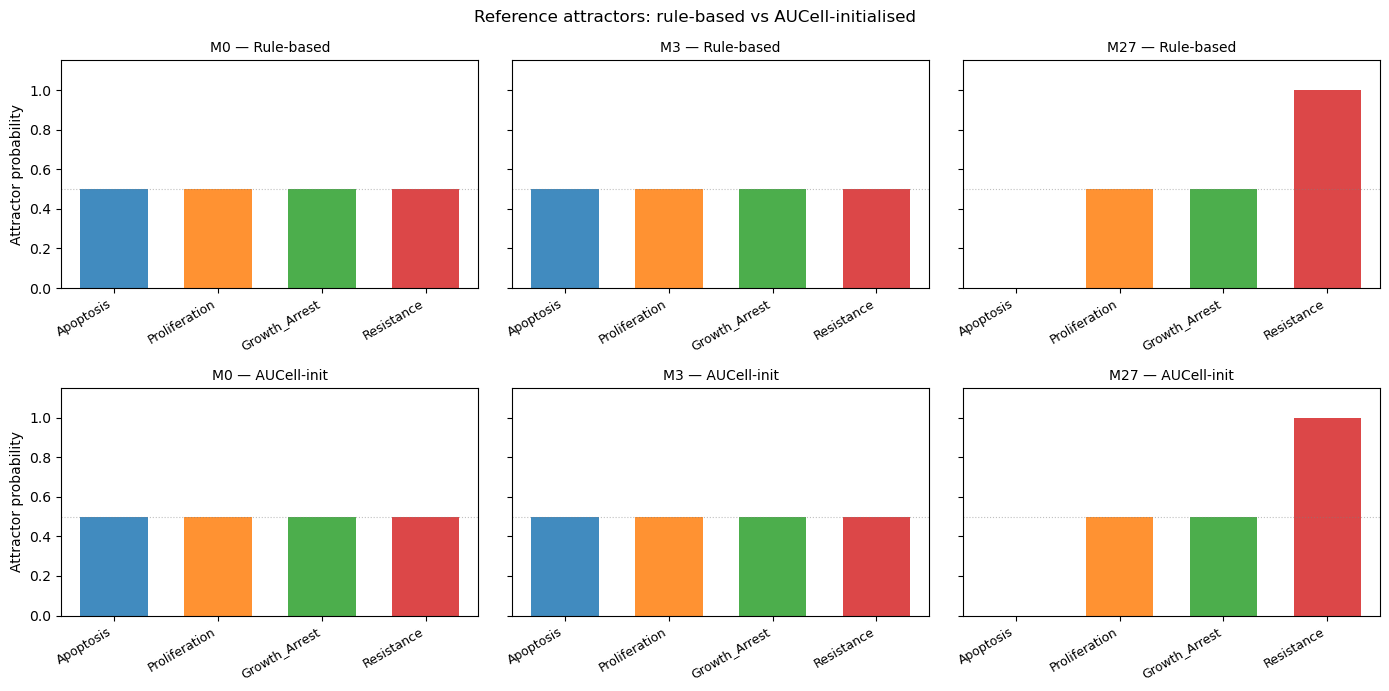

Saved: reference_attractors.csv
Screen-eligible nodes: 30


In [55]:
print('=== Reference attractors ===\n')
REF_ATTRACTORS     = {}   # AUCell-initialised (primary)
REF_ATTRACTORS_RULE = {}  # rule-based (comparison)

for cond in ['M0','M3','M27']:
    # AUCell-initialised
    sim_a = build_sim_aucell(cond)
    fin_a, _ = run_sim(sim_a)
    REF_ATTRACTORS[cond] = fin_a

    # Rule-based
    sim_r = build_sim_static(cond)
    fin_r, _ = run_sim(sim_r)
    REF_ATTRACTORS_RULE[cond] = fin_r

    print(f'{cond} AUCell-init : {" ".join(f"{k}={v:.3f}" for k,v in fin_a.items())}')
    print(f'{cond} rule-based  : {" ".join(f"{k}={v:.3f}" for k,v in fin_r.items())}')
    print()

# ── Bar chart comparison ──────────────────────────────────────────────────────
node_colors = {'Apoptosis':'#1f77b4','Proliferation':'#ff7f0e',
               'Growth_Arrest':'#2ca02c','Resistance':'#d62728'}
fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharey=True)
x, w = np.arange(len(OUTPUT_NODES)), 0.65

for col, cond in enumerate(['M0','M3','M27']):
    for row, (label, res) in enumerate([
        ('Rule-based', REF_ATTRACTORS_RULE),
        ('AUCell-init', REF_ATTRACTORS)
    ]):
        ax = axes[row, col]
        vals = [res[cond].get(n, 0) for n in OUTPUT_NODES]
        ax.bar(x, vals, color=[node_colors[n] for n in OUTPUT_NODES],
               alpha=0.85, width=w)
        ax.set_ylim(0, 1.15)
        ax.set_xticks(x)
        ax.set_xticklabels(OUTPUT_NODES, rotation=30, ha='right', fontsize=9)
        ax.set_title(f'{cond} — {label}', fontsize=10)
        ax.axhline(0.5, color='gray', linestyle=':', linewidth=0.8, alpha=0.5)
        if col == 0: ax.set_ylabel('Attractor probability', fontsize=10)

plt.suptitle('Reference attractors: rule-based vs AUCell-initialised', fontsize=12)
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/reference_attractors_comparison.pdf',
            dpi=300, bbox_inches='tight')
plt.show()

# Save
rows = []
for cond in ['M0','M3','M27']:
    for label, res in [('rule_based',REF_ATTRACTORS_RULE),('aucell',REF_ATTRACTORS)]:
        row = {'condition':cond,'init':label}; row.update(res[cond]); rows.append(row)
pd.DataFrame(rows).to_csv(f'{OUTPUT_DIR}/reference_attractors.csv', index=False)
print('Saved: reference_attractors.csv')
screen_nodes = [n for n in __import__('re').findall(r'^Node (\w+)', open(BND_FILE).read(), 8)
               if n not in {'VEGFA','IL3','GH1','HNRNPK','PLCG2_mutant',
                             'Apoptosis','Proliferation','Growth_Arrest','Resistance'}]
print(f'Screen-eligible nodes: {len(screen_nodes)}')

---
## 6. Main PK-coupled simulation — AUCell M0 start

**Question:** How do the four phenotypic attractors evolve month-by-month
from the AUCell-grounded M0 transcriptomic state under the observed
ibrutinib exposure profile?

Month 0 is initialised from AUCell M0 TF states. From month 1 onwards,
state chaining propagates the attractor distribution forward. BTK rate_up
is set from the monthly trough; PLCG2_mutant probability from cumulative AUC.

In [65]:
all_results   = []
prev_state    = None
months_to_run = sorted(monthly_stats['month'].unique())

print(f'Running {len(months_to_run)} months × {N_REPS} replicates')
print(f'M0 initialised from AUCell transcriptomic state\n')
print(f'{"Month":>6}  {"BTK":>7}  {"P_mut":>6}  {"Apopt":>7}  {"Resist":>7}  {"Prolif":>7}    {"Growth_A":>7}')
print('-'*70)

for month in months_to_run:
    row_pk    = monthly_stats[monthly_stats['month'] == month].iloc[0]
    btk_rate  = float(row_pk['btk_rate_up'])
    trough_c  = float(row_pk['trough_conc'])
    inhibition = float(row_pk['inhibition'])
    cum_auc   = float(row_pk['cum_auc_end_of_month'])
    p_mut     = plcg2_mut_prob(month)

    month_rows = []
    for rep in range(N_REPS):
        try:
            sim   = build_pk_sim(month, btk_rate, prev_state)
            final, _ = run_sim(sim)
            final.update({'month':month,'replicate':rep,'init':'aucell_M0',
                          'btk_rate_up':btk_rate,'trough_conc':trough_c,
                          'cum_auc':cum_auc,'inhibition':inhibition,
                          'p_plcg2_mut':p_mut})
            month_rows.append(final)
        except Exception as e:
            print(f'  SKIP M{month} rep{rep}: {e}')

    if month_rows:
        all_results.extend(month_rows)
        month_df   = pd.DataFrame(month_rows)
        prev_state = {col: month_df[col].mean() for col in month_df.columns
                      if col not in ['month','replicate','init','btk_rate_up',
                                     'trough_conc','cum_auc','inhibition','p_plcg2_mut']}
        print(f'  M{int(month):2d}    {btk_rate:7.3f}  {p_mut:6.3f}  '
              f'{prev_state.get("Apoptosis",float("nan")):7.3f}  '
              f'{prev_state.get("Resistance",float("nan")):7.3f}  '
              f'{prev_state.get("Proliferation",float("nan")):7.3f}  '
              f'{prev_state.get("Growth_Arrest",float("nan")):7.3f}')

results_df = pd.DataFrame(all_results)
results_df.to_csv(f'{OUTPUT_DIR}/pk_aucell_M0_replicates.csv', index=False)
print(f'\nSaved: pk_aucell_M0_replicates.csv ({len(results_df)} rows)')

Running 28 months × 50 replicates
M0 initialised from AUCell transcriptomic state

 Month      BTK   P_mut    Apopt   Resist   Prolif    Growth_A
----------------------------------------------------------------------
  M 0      0.486   0.005    0.497    0.503    0.500    0.499
  M 1      0.573   0.006    0.496    0.503    0.500    0.499
  M 2      0.349   0.008    0.495    0.504    0.500    0.499
  M 3      0.338   0.011    0.494    0.506    0.500    0.499
  M 4      0.357   0.014    0.492    0.508    0.500    0.499
  M 5      0.357   0.019    0.490    0.510    0.500    0.499
  M 6      0.358   0.026    0.486    0.513    0.500    0.499
  M 7      0.357   0.035    0.482    0.518    0.500    0.499
  M 8      0.357   0.046    0.476    0.524    0.500    0.499
  M 9      0.358   0.062    0.469    0.531    0.500    0.499
  M10      0.357   0.081    0.459    0.541    0.500    0.499
  M11      0.358   0.107    0.446    0.554    0.500    0.499
  M12      0.357   0.140    0.430    0.570    0.500

---
## 7. PK-coupled trajectories from M3 and M27 AUCell starting states

**Question:** How do the trajectories differ when starting from the M3 or M27
transcriptomic states rather than M0?

This is the key comparison that motivated moving AUCell initialisation to the
beginning of the pipeline. Starting from M0, the network begins in a
proliferative, partially resistant state and drug-induced apoptosis dominates
as BTK inhibition kicks in. Starting from M27, the network begins already in
the resistance basin — TFs associated with resistance (JUN, JUNB, MYC via
NF-κB bypass) are pre-activated from the scRNA-seq data — and resistance
persists or rises even under ibrutinib. This provides mechanistic evidence that
M27 resistance reflects a pre-existing transcriptional programme already
encoded at diagnosis, consistent with the trajectory inference finding of no
stable M3→M27 transition.

In [ ]:
def run_pk_from_start(start_cond, label):
    """
    PK-coupled simulation starting from AUCell-initialised condition state,
    beginning at the clinically relevant month (Option 2).

    M0 → runs months 0–27 (full course)
    M3 → runs months 3–27 (already in drug-response state at M3)
    M27 → runs month 27 only (reference point)

    First step uses build_sim_aucell(start_cond) — applies pharmacological
    locks + AUCell TF states — then overrides BTK rate with actual PK.
    From next month onwards: standard state chaining via build_pk_sim().
    """
    START_MONTH   = {'M0': 0, 'M3': 3, 'M27': 27}
    start_m       = START_MONTH[start_cond]
    months_subset = [m for m in months_to_run if m >= start_m]
    prev_state    = None
    results       = []

    print(f'\n[{label}] Starting at M{start_m}, '
          f'running {len(months_subset)} months ({start_m}→{months_subset[-1]})')

    for month in months_subset:
        row_pk   = monthly_stats[monthly_stats['month'] == month].iloc[0]
        btk_rate = float(row_pk['btk_rate_up'])
        cum_auc  = float(row_pk['cum_auc_end_of_month'])
        p_mut    = plcg2_mut_prob(month)

        month_rows = []
        for rep in range(N_REPS):
            try:
                if month == start_m and prev_state is None:
                    # First step: AUCell + pharmacological locks for condition
                    sim = build_sim_aucell(start_cond)
                    # Override BTK with actual PK rate for this month
                    sim.network['BTK'].set_rate(str(round(btk_rate, 6)), '1.0')
                    # PLCG2_mutant from AUC model
                    if p_mut <= 0.001:   sim.mutate('PLCG2_mutant', 'OFF')
                    elif p_mut >= 0.999: sim.mutate('PLCG2_mutant', 'ON')
                    else: sim.network.set_istate('PLCG2_mutant', [1-p_mut, p_mut])
                else:
                    sim = build_pk_sim(month, btk_rate, prev_state)

                final, _ = run_sim(sim)
                final.update({
                    'month':           month,
                    'replicate':       rep,
                    'start_condition': start_cond,
                    'label':           label,
                    'btk_rate_up':     btk_rate,
                    'cum_auc':         cum_auc,
                    'p_plcg2_mut':     p_mut,
                })
                month_rows.append(final)
            except Exception as e:
                print(f'  SKIP M{month} rep{rep}: {e}')

        if month_rows:
            results.extend(month_rows)
            df_m = pd.DataFrame(month_rows)
            prev_state = {
                col: df_m[col].mean() for col in df_m.columns
                if col not in ['month','replicate','start_condition',
                               'label','btk_rate_up','cum_auc','p_plcg2_mut']
            }
            print(f'  M{int(month):2d}: BTK={btk_rate:.3f}  P_mut={p_mut:.3f}  '
                  f'Resist={prev_state.get("Resistance",float("nan")):.3f}  '
                  f'Apopt={prev_state.get("Apoptosis",float("nan")):.3f}')

    return pd.DataFrame(results)


print('Running M3 start (months 3→27)...')
df_from_M3  = run_pk_from_start('M3',  'Start M3 (AUCell)')
print('\nRunning M27 start (month 27 only)...')
df_from_M27 = run_pk_from_start('M27', 'Start M27 (AUCell)')

df_all_starts = pd.concat([
    results_df.assign(label='Start M0 (AUCell)'),
    df_from_M3,
    df_from_M27,
], ignore_index=True)
df_all_starts.to_csv(f'{OUTPUT_DIR}/pk_all_starting_states.csv', index=False)
print(f'\nSaved: pk_all_starting_states.csv ({len(df_all_starts)} rows)')

---
## 8. Trajectory comparison: M0 vs M3 vs M27 starting states

**Question:** How much does the transcriptomic starting state determine the
eventual phenotypic outcome under identical PK exposure?

The three-panel figure shows Resistance, Apoptosis, and Growth_Arrest
trajectories for all three starting states. The difference panel (bottom)
shows M27 start minus M0 start — positive values indicate months where the
M27-initialised network is more resistant than the M0-initialised one.

In [ ]:
start_styles = {
    'Start M0 (AUCell)':  {'color':'#2ca02c','ls':'-',  'marker':'o'},
    'Start M3 (AUCell)':  {'color':'#1f77b4','ls':'--', 'marker':'s'},
    'Start M27 (AUCell)': {'color':'#d62728','ls':':',  'marker':'^'},
}

fig, axes = plt.subplots(2, 3, figsize=(16, 9), sharex=True)
plot_nodes = ['Resistance', 'Apoptosis', 'Growth_Arrest']

for col, node in enumerate(plot_nodes):
    ax_top  = axes[0, col]
    ax_diff = axes[1, col]

    for label, style in start_styles.items():
        sub  = df_all_starts[df_all_starts['label'] == label]
        grp  = sub.groupby('month')[node]
        mean = grp.mean(); q25 = grp.quantile(0.25); q75 = grp.quantile(0.75)
        ax_top.plot(mean.index, mean.values, color=style['color'],
                    linestyle=style['ls'], marker=style['marker'],
                    linewidth=2, markersize=4, label=label)
        ax_top.fill_between(mean.index, q25.values, q75.values,
                            alpha=0.10, color=style['color'])

    for xv, lbl in [(3,'M3'),(27,'M27')]:
        ax_top.axvline(xv, color='gray', linestyle=':', alpha=0.5)
        ax_top.text(xv+0.3, 1.07, lbl, fontsize=8, color='gray')
    ax_top.set_ylim(-0.05, 1.15)
    ax_top.set_ylabel(f'{node} probability', fontsize=10)
    ax_top.set_title(node, fontsize=11)
    if col == 0: ax_top.legend(fontsize=8, loc='upper right')

    # Difference: M27 start − M0 start
    mean_m0  = df_all_starts[df_all_starts['label']=='Start M0 (AUCell)']               .groupby('month')[node].mean()
    mean_m27 = df_all_starts[df_all_starts['label']=='Start M27 (AUCell)']               .groupby('month')[node].mean()
    common = mean_m0.index.intersection(mean_m27.index)
    diff   = mean_m27.loc[common] - mean_m0.loc[common]
    ax_diff.bar(common, diff.values,
                color=['#d62728' if v>0 else '#2ca02c' for v in diff.values],
                alpha=0.75)
    ax_diff.axhline(0, color='black', linewidth=0.8)
    ax_diff.set_ylabel(f'Δ{node}\n(M27−M0)', fontsize=9)
    ax_diff.set_xlabel('Month', fontsize=10)

plt.suptitle('PK-coupled trajectories by AUCell starting state\n'
             'Top: attractor probabilities | Bottom: M27 start − M0 start',
             fontsize=12)
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/pk_starting_state_comparison.pdf',
            dpi=300, bbox_inches='tight')
plt.savefig(f'{OUTPUT_DIR}/pk_starting_state_comparison.svg', bbox_inches='tight')
plt.show()

print('\n=== Summary at M27 ===')
for label in start_styles:
    sub = df_all_starts[(df_all_starts['label']==label) &
                        (df_all_starts['month']==27)]
    if not sub.empty:
        vals = '  '.join(f'{n}={sub[n].mean():.3f}' for n in OUTPUT_NODES)
        print(f'  {label}: {vals}')

---
## 9. Results summary, trajectory figure, replicate variability

Summary statistics and main figures for the primary (M0-start) PK-coupled
simulation.

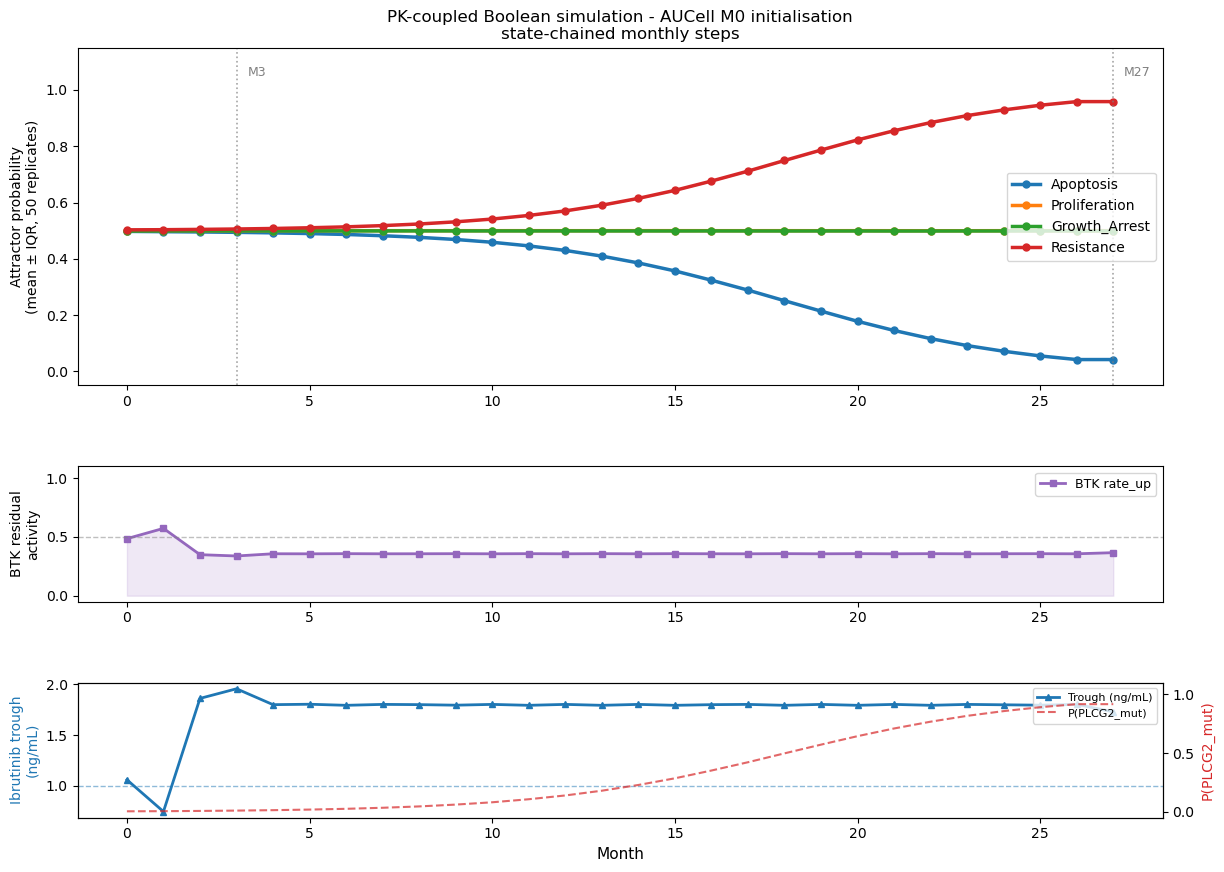

In [66]:
summary_df = (
    results_df.groupby('month')[OUTPUT_NODES+['btk_rate_up','p_plcg2_mut']]
    .agg(['mean','std',
          lambda x: np.percentile(x,25),
          lambda x: np.percentile(x,75)])
)
summary_df.columns = ['_'.join(c).replace('<lambda_0>','q25').replace('<lambda_1>','q75')
                      for c in summary_df.columns]
summary_df = summary_df.reset_index()
summary_df.to_csv(f'{OUTPUT_DIR}/pk_monthly_summary.csv', index=False)

node_colors = {'Apoptosis':'#1f77b4','Proliferation':'#ff7f0e',
               'Growth_Arrest':'#2ca02c','Resistance':'#d62728'}
months_plot = summary_df['month'].values

fig = plt.figure(figsize=(14, 10))
gs  = gridspec.GridSpec(3, 1, figure=fig, hspace=0.4, height_ratios=[3,1.2,1.2])

ax1 = fig.add_subplot(gs[0])
for node, color in node_colors.items():
    ax1.plot(months_plot, summary_df[f'{node}_mean'], '-o',
             color=color, linewidth=2.5, markersize=5, label=node)
    ax1.fill_between(months_plot, summary_df[f'{node}_q25'],
                     summary_df[f'{node}_q75'], alpha=0.15, color=color)
for xv, lbl in [(3,'M3'),(27,'M27')]:
    ax1.axvline(xv, color='gray', linestyle=':', linewidth=1.2, alpha=0.7)
    ax1.text(xv+0.3, 1.05, lbl, fontsize=9, color='gray')
ax1.set_ylim(-0.05, 1.15)
ax1.set_ylabel('Attractor probability\n(mean ± IQR, 50 replicates)', fontsize=10)
ax1.legend(loc='center right', fontsize=10)
ax1.set_title('PK-coupled Boolean simulation - AUCell M0 initialisation\n'
              'state-chained monthly steps', fontsize=12)

ax2 = fig.add_subplot(gs[1], sharex=ax1)
ax2.plot(months_plot, summary_df['btk_rate_up_mean'], '-s',
         color='#9467bd', linewidth=2, markersize=4, label='BTK rate_up')
ax2.fill_between(months_plot, 0, summary_df['btk_rate_up_mean'],
                 alpha=0.15, color='#9467bd')
ax2.axhline(0.5, color='gray', linestyle='--', linewidth=1, alpha=0.5)
ax2.set_ylim(-0.05, 1.1); ax2.set_ylabel('BTK residual\nactivity', fontsize=10)
ax2.legend(fontsize=9)

ax3 = fig.add_subplot(gs[2], sharex=ax1)
ax3t = ax3.twinx()
ax3.plot(monthly_stats['month'], monthly_stats['trough_conc'], '-^',
         color='#1f77b4', linewidth=2, markersize=4, label='Trough (ng/mL)')
ax3.axhline(IC50_NG_ML, color='#1f77b4', linestyle='--', linewidth=1, alpha=0.5)
ax3.set_ylabel('Ibrutinib trough\n(ng/mL)', fontsize=10, color='#1f77b4')
ax3t.plot(months_plot, [plcg2_mut_prob(m) for m in months_plot],
          '--', color='#d62728', linewidth=1.5, alpha=0.7, label='P(PLCG2_mut)')
ax3t.set_ylim(-0.05, 1.1)
ax3t.set_ylabel('P(PLCG2_mut)', fontsize=10, color='#d62728')
ax3.set_xlabel('Month', fontsize=11)
lines1, lab1 = ax3.get_legend_handles_labels()
lines2, lab2 = ax3t.get_legend_handles_labels()
ax3.legend(lines1+lines2, lab1+lab2, fontsize=8, loc='upper right')

plt.savefig(f'{OUTPUT_DIR}/pk_trajectory_main.pdf', dpi=300, bbox_inches='tight')
plt.savefig(f'{OUTPUT_DIR}/pk_trajectory_main.svg', bbox_inches='tight')
plt.show()

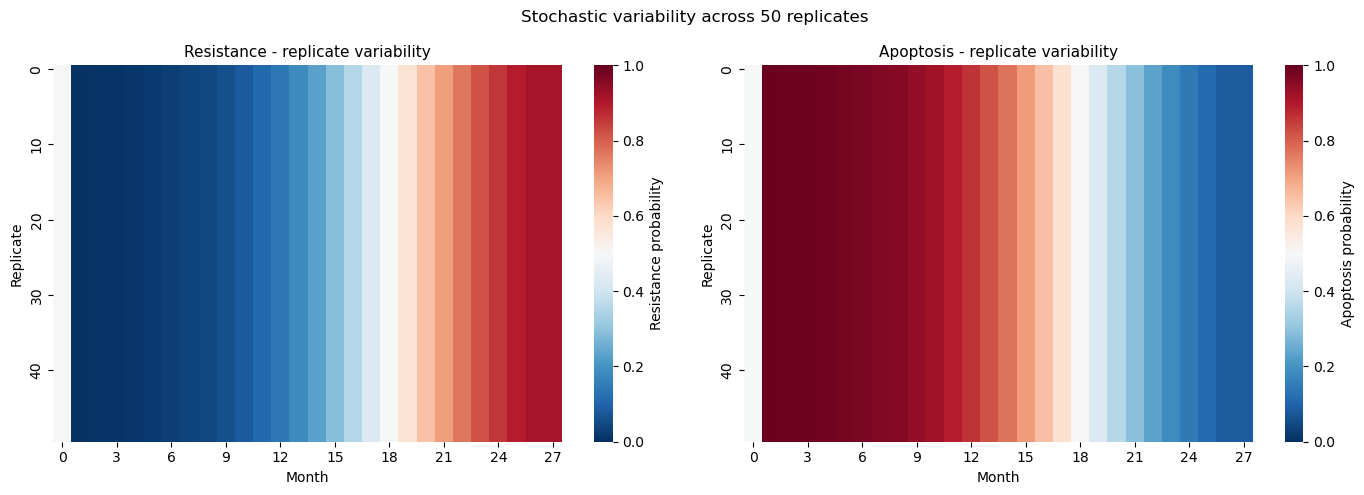

In [31]:
# ── Replicate variability heatmap ─────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, node in [(axes[0],'Resistance'),(axes[1],'Apoptosis')]:
    pivot = results_df.pivot_table(
        index='replicate', columns='month', values=node, aggfunc='mean')
    sns.heatmap(pivot, ax=ax, cmap='RdBu_r', center=0.5, vmin=0, vmax=1,
                cbar_kws={'label':f'{node} probability'},
                xticklabels=3, yticklabels=10)
    ax.set_title(f'{node} - replicate variability', fontsize=11)
    ax.set_xlabel('Month', fontsize=10); ax.set_ylabel('Replicate', fontsize=10)
plt.suptitle('Stochastic variability across 50 replicates', fontsize=12)
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/pk_replicate_heatmap.pdf', dpi=300, bbox_inches='tight')
plt.show()

---
## 10. Sensitivity analysis — IC50 uncertainty

**Question:** How sensitive is the resistance trajectory to the assumed IC50?
Published estimates range from 0.5 to 5 ng/mL. The simulation restarts from
AUCell M0 initial states at each IC50 value.


IC50 = 0.5 ng/mL ...
  M 0: BTK=0.321  Resist=0.503    M 1: BTK=0.402  Resist=0.503    M 2: BTK=0.212  Resist=0.504    M 3: BTK=0.204  Resist=0.506    M 4: BTK=0.217  Resist=0.508    M 5: BTK=0.217  Resist=0.510    M 6: BTK=0.218  Resist=0.513    M 7: BTK=0.217  Resist=0.518    M 8: BTK=0.217  Resist=0.524    M 9: BTK=0.218  Resist=0.531    M10: BTK=0.217  Resist=0.541    M11: BTK=0.218  Resist=0.554    M12: BTK=0.217  Resist=0.570    M13: BTK=0.218  Resist=0.590    M14: BTK=0.217  Resist=0.615    M15: BTK=0.218  Resist=0.643    M16: BTK=0.217  Resist=0.676    M17: BTK=0.217  Resist=0.711    M18: BTK=0.218  Resist=0.749    M19: BTK=0.217  Resist=0.786    M20: BTK=0.218  Resist=0.822    M21: BTK=0.217  Resist=0.855    M22: BTK=0.218  Resist=0.884    M23: BTK=0.217  Resist=0.909    M24: BTK=0.218  Resist=0.929    M25: BTK=0.218  Resist=0.946    M26: BTK=0.217  Resist=0.959    M27: BTK=0.224  Resist=0.959  

IC50 = 1.0 ng/mL ...
  M 0: BTK=0.486  Resist=0.503    M 1: BTK=0.573  Resist=0.

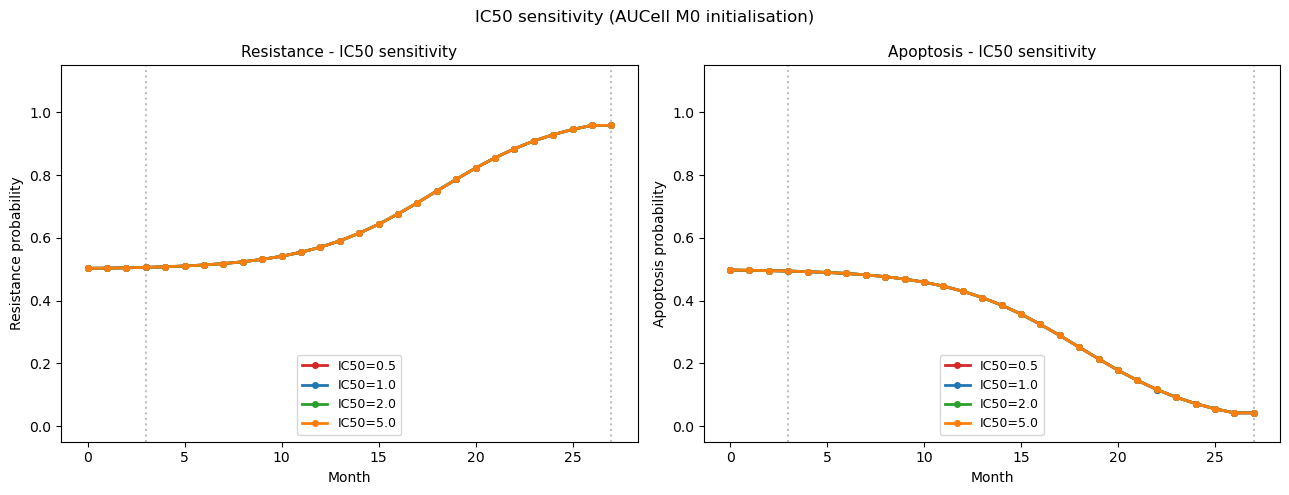

In [67]:
IC50_GRID       = [0.5, 1.0, 2.0, 5.0]
N_REPS_SENS     = 10
months_to_run_s = sorted(monthly_stats['month'].unique())
sens_results    = []

for ic50 in IC50_GRID:
    print(f'\nIC50 = {ic50} ng/mL ...', flush=True)
    prev_s = None
    for month in months_to_run_s:
        row_pk   = monthly_stats[monthly_stats['month'] == month].iloc[0]
        btk_rate = conc_to_btk_rate(float(row_pk['trough_conc']), IC50=ic50)
        p_mut    = plcg2_mut_prob(month)
        rows_s   = []
        for rep in range(N_REPS_SENS):
            try:
                sim = build_pk_sim(month, btk_rate, prev_s)
                final, _ = run_sim(sim)
                final.update({'month':month,'replicate':rep,
                              'IC50':ic50,'btk_rate_up':btk_rate,'p_plcg2_mut':p_mut})
                rows_s.append(final)
            except Exception as e:
                print(f'  SKIP: {e}')
        if rows_s:
            sens_results.extend(rows_s)
            df_s   = pd.DataFrame(rows_s)
            prev_s = {c: df_s[c].mean() for c in df_s.columns
                      if c not in ['month','replicate','IC50','btk_rate_up','p_plcg2_mut']}
        print(f'  M{int(month):2d}: BTK={btk_rate:.3f}  '
              f'Resist={prev_s.get("Resistance",float("nan")):.3f}', end='  ')
    print()

sens_df = pd.DataFrame(sens_results)
sens_df.to_csv(f'{OUTPUT_DIR}/sensitivity_ic50.csv', index=False)
ic50_colors = {0.5:'#d62728',1.0:'#1f77b4',2.0:'#2ca02c',5.0:'#ff7f0e'}
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, node in [(axes[0],'Resistance'),(axes[1],'Apoptosis')]:
    for ic50 in IC50_GRID:
        grp = sens_df[sens_df['IC50']==ic50].groupby('month')[node].mean().reset_index()
        ax.plot(grp['month'], grp[node], '-o', color=ic50_colors[ic50],
                linewidth=2, markersize=4, label=f'IC50={ic50}')
    for xv in [3,27]: ax.axvline(xv, color='gray', linestyle=':', alpha=0.5)
    ax.set_ylim(-0.05, 1.15); ax.set_xlabel('Month', fontsize=10)
    ax.set_ylabel(f'{node} probability', fontsize=10)
    ax.set_title(f'{node} - IC50 sensitivity', fontsize=11); ax.legend(fontsize=9)
plt.suptitle('IC50 sensitivity (AUCell M0 initialisation)', fontsize=12)
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/sensitivity_ic50.pdf', dpi=300, bbox_inches='tight')
plt.show()

---
## 11. Sensitivity analysis — AUC₅₀ fraction (PLCG2_mutant timing)

**Question:** How sensitive is the resistance emergence month to the assumed
PLCG2_mutant clonal expansion timing?
Lower fraction → earlier dominance; higher fraction → later.


frac=0.40  AUC_50=3704  P=0.5 at M11
  M 0: P_mut=0.049  Resist=0.525    M 1: P_mut=0.060  Resist=0.530    M 2: P_mut=0.080  Resist=0.541    M 3: P_mut=0.106  Resist=0.553    M 4: P_mut=0.138  Resist=0.570    M 5: P_mut=0.178  Resist=0.590    M 6: P_mut=0.226  Resist=0.614    M 7: P_mut=0.284  Resist=0.642    M 8: P_mut=0.348  Resist=0.675    M 9: P_mut=0.420  Resist=0.711    M10: P_mut=0.494  Resist=0.748    M11: P_mut=0.570  Resist=0.785    M12: P_mut=0.641  Resist=0.821    M13: P_mut=0.708  Resist=0.854    M14: P_mut=0.766  Resist=0.883    M15: P_mut=0.815  Resist=0.908    M16: P_mut=0.857  Resist=0.929    M17: P_mut=0.890  Resist=0.945    M18: P_mut=0.916  Resist=0.958    M19: P_mut=0.936  Resist=0.968    M20: P_mut=0.952  Resist=0.976    M21: P_mut=0.964  Resist=0.982    M22: P_mut=0.973  Resist=0.987    M23: P_mut=0.980  Resist=0.990    M24: P_mut=0.985  Resist=0.993    M25: P_mut=0.989  Resist=0.995    M26: P_mut=0.992  Resist=0.996    M27: P_mut=0.992  Resist=0.996  

frac=0.5

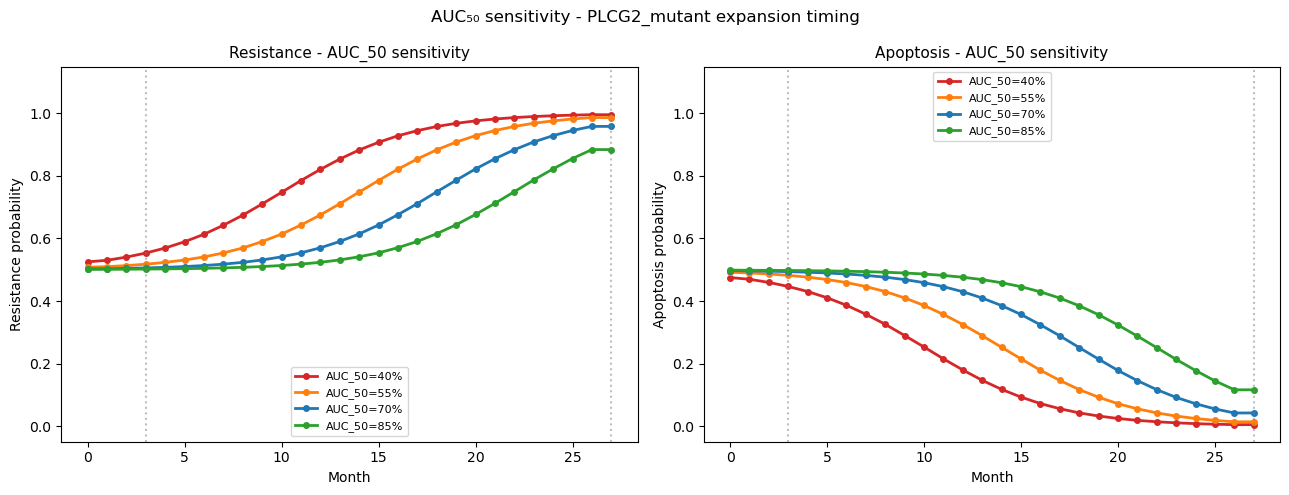

In [68]:
AUC_FRACTION_GRID = [0.40, 0.55, 0.70, 0.85]
N_REPS_AUC        = 10
months_to_run_a   = sorted(monthly_stats['month'].unique())
auc_sens_results  = []

for frac in AUC_FRACTION_GRID:
    a50 = total_auc_M27 * frac
    k_s = 8.0 / total_auc_M27

    def p_s(m, a50=a50, k=k_s):
        row = monthly_stats[monthly_stats['month']==m]
        if row.empty: return 0.0
        cum = float(row['cum_auc_end_of_month'].values[0])
        return 0.0 if cum<=0 else 1.0/(1.0+np.exp(-k*(cum-a50)))

    cross = next((m for m in months_to_run_a if p_s(m) >= 0.5), None)
    print(f'\nfrac={frac:.2f}  AUC_50={a50:.0f}  P=0.5 at M{int(cross) if cross else "never"}')

    prev_a = None
    for month in months_to_run_a:
        row_pk   = monthly_stats[monthly_stats['month']==month].iloc[0]
        btk_rate = float(row_pk['btk_rate_up'])
        p_mut    = p_s(month)
        rows_a   = []
        for rep in range(N_REPS_AUC):
            try:
                sim = build_pk_sim(month, btk_rate, prev_a)
                if p_mut<=0.001:   sim.mutate('PLCG2_mutant','OFF')
                elif p_mut>=0.999: sim.mutate('PLCG2_mutant','ON')
                else:              sim.network.set_istate('PLCG2_mutant',[1-p_mut,p_mut])
                final, _ = run_sim(sim)
                final.update({'month':month,'replicate':rep,
                              'AUC_50_fraction':frac,'p_plcg2_mut':p_mut})
                rows_a.append(final)
            except Exception as e:
                print(f'  SKIP: {e}')
        if rows_a:
            auc_sens_results.extend(rows_a)
            df_a  = pd.DataFrame(rows_a)
            prev_a = {c: df_a[c].mean() for c in df_a.columns
                      if c not in ['month','replicate','AUC_50_fraction','p_plcg2_mut']}
        print(f'  M{int(month):2d}: P_mut={p_mut:.3f}  '
              f'Resist={prev_a.get("Resistance",float("nan")):.3f}', end='  ')
    print()

auc_sens_df = pd.DataFrame(auc_sens_results)
auc_sens_df.to_csv(f'{OUTPUT_DIR}/sensitivity_auc50.csv', index=False)
frac_colors = {0.40:'#d62728',0.55:'#ff7f0e',0.70:'#1f77b4',0.85:'#2ca02c'}
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, node in [(axes[0],'Resistance'),(axes[1],'Apoptosis')]:
    for frac in AUC_FRACTION_GRID:
        grp = auc_sens_df[auc_sens_df['AUC_50_fraction']==frac]              .groupby('month')[node].mean().reset_index()
        ax.plot(grp['month'], grp[node], '-o', color=frac_colors[frac],
                linewidth=2, markersize=4, label=f'AUC_50={frac*100:.0f}%')
    for xv in [3,27]: ax.axvline(xv, color='gray', linestyle=':', alpha=0.5)
    ax.set_ylim(-0.05,1.15); ax.set_xlabel('Month',fontsize=10)
    ax.set_ylabel(f'{node} probability',fontsize=10)
    ax.set_title(f'{node} - AUC_50 sensitivity',fontsize=11); ax.legend(fontsize=8)
plt.suptitle('AUC₅₀ sensitivity - PLCG2_mutant expansion timing', fontsize=12)
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/sensitivity_auc50.pdf', dpi=300, bbox_inches='tight')
plt.show()

---
## 12. Transition detection

**Question:** At which month does the model predict resistance emergence,
loss of apoptotic response, and proliferation recovery?

In [69]:
monthly_mean = results_df.groupby('month')[OUTPUT_NODES].mean().reset_index()

def first_crossing(series, months, threshold, direction='above'):
    for m, v in zip(months, series):
        if direction=='above' and v>=threshold: return m
        if direction=='below' and v<=threshold: return m
    return None

m_resist = first_crossing(monthly_mean['Resistance'], monthly_mean['month'], 0.5, 'above')
m_apopt  = first_crossing(monthly_mean['Apoptosis'],  monthly_mean['month'], 0.5, 'below')
m_prolif = first_crossing(monthly_mean['Proliferation'], monthly_mean['month'], 0.3, 'above')

print('=== Transition summary (AUCell M0-initialised) ===')
print(f'Resistance > 0.5:      M{int(m_resist) if m_resist else "never"}')
print(f'Apoptosis drops < 0.5: M{int(m_apopt)  if m_apopt  else "never"}')
print(f'Proliferation > 0.3:   M{int(m_prolif) if m_prolif else "never"}')

pd.DataFrame([{
    'IC50_ng_ml':IC50_NG_ML,'AUC_50_fraction':AUC_50_FRACTION,
    'AUCELL_THRESHOLD':AUCELL_THRESHOLD,
    'month_resistance_emerges':m_resist,
    'month_apoptosis_lost':m_apopt,
    'month_proliferation_recovered':m_prolif,
}]).to_csv(f'{OUTPUT_DIR}/transitions.csv', index=False)
print('Saved: transitions.csv')

=== Transition summary (AUCell M0-initialised) ===
Resistance > 0.5:      Mnever
Apoptosis drops < 0.5: Mnever
Proliferation > 0.3:   Mnever
Saved: transitions.csv


---
## 13. Supplementary analyses — shared helpers

S1–S5 use `build_sim_aucell()` throughout — the same AUCell threshold and
TF states derived in Section 3. REF_ATTRACTORS (AUCell-initialised) are
the reference for all delta computations.

In [71]:
# ── v6 supplementary setup ────────────────────────────────────────────────────
# SYK removed from RESISTANCE_INPUTS (it feeds PI3K, not Resistance directly)
# SOS1 retained in MAPK_ERK (sole RAS activator in v6: SOS1→RAS)
# EPO/GH1/Wnt/VEGFA/TCF removed from EXCLUDE_FROM_SCREEN (not in v6)

PATHWAY_CLASSES = {
    'MAPK_ERK':  ['ERK','MEK','RAF1','RAS','SOS1','PCBP2'],
    'PI3K_MTOR': ['PI3K','AKT','MTOR','PTEN'],
    'BCR_bypass':['BTK','PLCG2'],
    'BCL2_fam':  ['BCL2L1','BCL2','MCL1','BAD'],
    'NF_kB_AP1': ['NFKB1','JUNB','JUN','STAT5'],
}

EXCLUDE_FROM_SCREEN = {
    'IL3', 'HNRNPK',              # constitutive inputs
    'PLCG2_mutant',               # somatic mutation lock
    'Apoptosis', 'Proliferation', 'Growth_Arrest', 'Resistance',  # outputs
}

def get_screen_nodes():
    """All dynamic nodes eligible for perturbation screens in v6."""    
    with open(BND_FILE) as f: bnd = f.read()
    return [n for n in _re.findall(r'^Node (\w+)', bnd, _re.MULTILINE)
            if n not in EXCLUDE_FROM_SCREEN]

def run_sim_static(sim):
    """Run static sim; return (final_dict, traj_df)."""    
    result = sim.run()
    traj   = result.get_nodes_probtraj()
    if any(n not in traj.columns for n in OUTPUT_NODES):
        raise RuntimeError('Output nodes missing from trajectory')
    return traj[OUTPUT_NODES].iloc[-1].to_dict(), traj[OUTPUT_NODES]

def bliss_score(E_A, E_B, E_AB):
    """Bliss independence synergy (positive = synergistic)."""    
    return E_AB - (E_A + E_B - E_A * E_B)

def select_top_per_class(screen_df, direction='OFF', score_col='delta_Resistance'):
    """Best perturbation per pathway class (most negative score_col)."""    
    selected = {}
    fb = 'ON' if direction == 'OFF' else 'OFF'
    for cls, members in PATHWAY_CLASSES.items():
        for d in [direction, fb]:
            sub = screen_df[
                screen_df['node'].isin(members) & (screen_df['direction'] == d)
            ]
            if not sub.empty:
                selected[cls] = (sub.loc[sub[score_col].idxmin(), 'node'], d)
                break
        if cls not in selected:
            print(f'  WARNING: no hits for class "{cls}"')
    return selected

screen_nodes = get_screen_nodes()
print(f'Screen-eligible nodes ({len(screen_nodes)}): {screen_nodes}')
print(f'\nREF_ATTRACTORS: {list(REF_ATTRACTORS.keys())} (AUCell-initialised)')
print('Supplementary helpers defined.')

Screen-eligible nodes (30): ['BTK', 'SYK', 'PLCG2', 'PTEN', 'MTOR', 'CEBPA', 'PCBP2', 'ERK', 'MEK', 'RAF1', 'SOS1', 'IL3RA', 'AKT', 'BAD', 'MYC', 'BAG1', 'BCL2L1', 'NFKB1', 'MCL1', 'PI3K', 'FOXO', 'BCL2L11_FASLG', 'RAS', 'JAK2', 'STAT5', 'BCL2', 'HCK', 'JUN', 'JUNB', 'GSK3B']

REF_ATTRACTORS: ['M0', 'M3', 'M27'] (AUCell-initialised)
Supplementary helpers defined.


---
## 14. S1 — Single-node perturbation screen at M27

**Question:** Which perturbations shift the AUCell-initialised M27 resistance
attractor towards apoptosis or reduce Resistance probability?

Screening 30 nodes × 2 directions (M27 AUCell-init)...


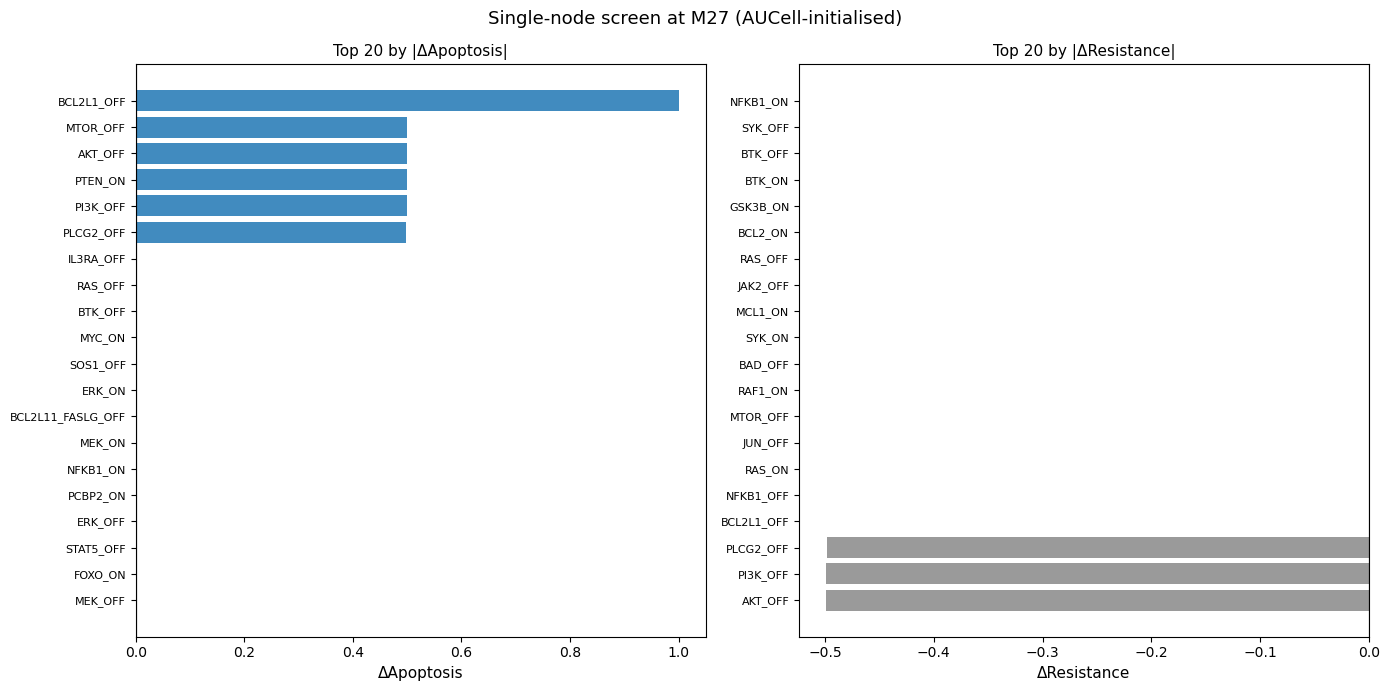

In [72]:
assert REF_ATTRACTORS.get('M27') is not None, 'Run Section 5 first'

screen_M27_rows = []
print(f'Screening {len(screen_nodes)} nodes × 2 directions (M27 AUCell-init)...')
for node in screen_nodes:
    for direction in ['OFF','ON']:
        sim = build_sim_aucell('M27')
        try:
            sim.mutate(node, direction)
            final, _ = run_sim_static(sim)
            screen_M27_rows.append({
                'node':node,'direction':direction,'perturbation':f'{node}_{direction}',
                'delta_Apoptosis':  final['Apoptosis']  - REF_ATTRACTORS['M27']['Apoptosis'],
                'delta_Resistance': final['Resistance'] - REF_ATTRACTORS['M27']['Resistance'],
                **{k:final[k] for k in OUTPUT_NODES}
            })
        except Exception as e:
            print(f'  SKIP {node} {direction}: {e}')

screen_M27_df = pd.DataFrame(screen_M27_rows)
screen_M27_df.to_csv(f'{OUTPUT_DIR}/S1_screen_M27.csv', index=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax, col, color, label in [
    (axes[0],'delta_Apoptosis', '#1f77b4','ΔApoptosis'),
    (axes[1],'delta_Resistance','#d62728','ΔResistance'),
]:
    top = screen_M27_df.reindex(screen_M27_df[col].abs().nlargest(20).index).sort_values(col)
    ax.barh(top['perturbation'], top[col],
            color=[color if v>0 else '#888888' for v in top[col]], alpha=0.85)
    ax.axvline(0, color='black', linewidth=0.8)
    ax.set_xlabel(label, fontsize=11); ax.set_title(f'Top 20 by |{label}|', fontsize=11)
    ax.tick_params(axis='y', labelsize=8)
plt.suptitle('Single-node screen at M27 (AUCell-initialised)', fontsize=13)
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/S1_screen_M27.pdf', dpi=300, bbox_inches='tight')
plt.show()

---
## 15. S1b — Single-node perturbation screen at M3

**Question:** Which perturbations, applied from the AUCell-initialised M3
drug-response state, would prevent or accelerate resistance emergence?

Screening 30 nodes × 2 directions (M3 AUCell-init)...


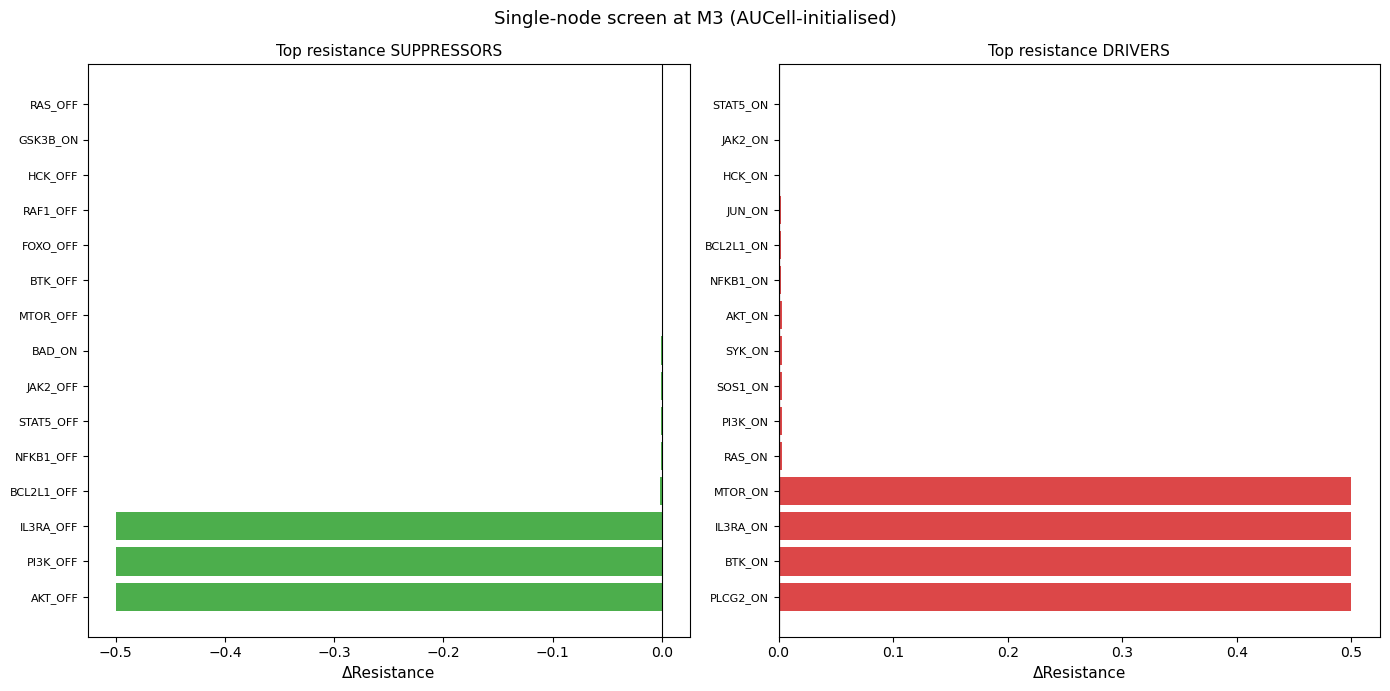

In [78]:
assert REF_ATTRACTORS.get('M3') is not None, 'Run Section 5 first'

screen_M3_rows = []
print(f'Screening {len(screen_nodes)} nodes × 2 directions (M3 AUCell-init)...')
for node in screen_nodes:
    for direction in ['OFF','ON']:
        sim = build_sim_aucell('M3')
        try:
            sim.mutate(node, direction)
            final, _ = run_sim_static(sim)
            screen_M3_rows.append({
                'node':node,'direction':direction,'perturbation':f'{node}_{direction}',
                'delta_Resistance': final['Resistance'] - REF_ATTRACTORS['M3']['Resistance'],
                'delta_Apoptosis':  final['Apoptosis']  - REF_ATTRACTORS['M3']['Apoptosis'],
                **{k:final[k] for k in OUTPUT_NODES}
            })
        except Exception as e:
            print(f'  SKIP {node} {direction}: {e}')

screen_M3_df = pd.DataFrame(screen_M3_rows)
assert 'delta_Resistance' in screen_M3_df.columns and len(screen_M3_df)>0
screen_M3_df.to_csv(f'{OUTPUT_DIR}/S1b_screen_M3.csv', index=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax, data, color, title in [
    (axes[0], screen_M3_df.nsmallest(15,'delta_Resistance').sort_values('delta_Resistance'),
     '#2ca02c','Top resistance SUPPRESSORS'),
    (axes[1], screen_M3_df.nlargest(15,'delta_Resistance').sort_values('delta_Resistance',ascending=False),
     '#d62728','Top resistance DRIVERS'),
]:
    ax.barh(data['perturbation'], data['delta_Resistance'], color=color, alpha=0.85)
    ax.axvline(0, color='black', linewidth=0.8)
    ax.set_xlabel('ΔResistance', fontsize=11); ax.set_title(title, fontsize=11)
    ax.tick_params(axis='y', labelsize=8)
plt.suptitle('Single-node screen at M3', fontsize=13)
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/S1b_screen_M3.pdf', dpi=300, bbox_inches='tight')
plt.show()

---
## 16. S2 — Cytokine rescue at M27

**Question:** Does restoring cytokine signalling shift the AUCell-initialised
M27 quiescent resistance attractor towards proliferation?

  M27 baseline         Prolif=0.500  Resist=1.000  Apopt=0.001
  + IL3                Prolif=0.999  Resist=1.000  Apopt=0.000


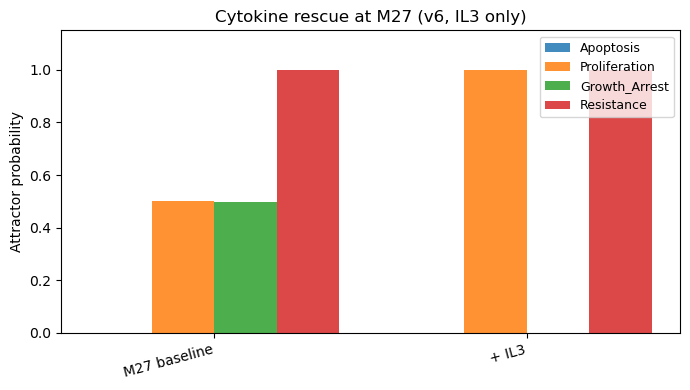

In [73]:
# S2 — Cytokine rescue at M27
# In v6, EPO and GH1 and their receptors (EPOR, GHR) have been removed.
# Only IL3 remains as the cytokine node (→ IL3RA).
# The rescue question: does restoring IL3 signalling convert quiescent
# ibrutinib-resistant CLL cells to a proliferative phenotype?

cytokine_conditions = [
    ('M27 baseline', []),
    ('+ IL3',        ['IL3']),
]
rescue_rows = []
for label, cyts in cytokine_conditions:
    sim = build_sim_aucell('M27')
    for cyt in cyts:
        sim.mutate(cyt, 'ON')
    final, _ = run_sim_static(sim)
    rescue_rows.append({'condition': label, **final})
    print(f'  {label:<20} Prolif={final["Proliferation"]:.3f}  '
          f'Resist={final["Resistance"]:.3f}  Apopt={final["Apoptosis"]:.3f}')

rescue_df = pd.DataFrame(rescue_rows).set_index('condition')
rescue_df.to_csv(f'{OUTPUT_DIR}/S2_cytokine_rescue.csv')

fig, ax = plt.subplots(figsize=(7, 4))
x, w = range(len(rescue_df)), 0.2
for i, (node, color) in enumerate(zip(OUTPUT_NODES,
                                       ['#1f77b4','#ff7f0e','#2ca02c','#d62728'])):
    ax.bar([xi+i*w for xi in x], rescue_df[node],
           width=w, label=node, color=color, alpha=0.85)
ax.set_xticks([xi+1.5*w for xi in x])
ax.set_xticklabels(rescue_df.index, rotation=15, ha='right', fontsize=10)
ax.set_ylabel('Attractor probability'); ax.set_ylim(0, 1.15)
ax.legend(loc='upper right', fontsize=9)
ax.set_title('Cytokine rescue at M27', fontsize=12)
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/S2_cytokine_rescue.pdf', dpi=300, bbox_inches='tight')
plt.show()

---
## 17. S3 — Bliss synergy screen (M3 background)

**Question:** Do any pairs of node knockouts synergistically prevent resistance
emergence from the AUCell-initialised M3 state?
Requires S1b (Section 15) to have been run.

Selected nodes (M3):
  MAPK_ERK       : RAF1 OFF  ΔR=+0.000
  PI3K_MTOR      : AKT OFF  ΔR=-0.500
  BCR_bypass     : BTK OFF  ΔR=+0.000
  BCL2_fam       : BCL2L1 OFF  ΔR=-0.002
  NF_kB_AP1      : NFKB1 OFF  ΔR=-0.001
  RAF1_OFF + AKT_OFF: Bliss=+0.000
  RAF1_OFF + BTK_OFF: Bliss=+0.000
  RAF1_OFF + BCL2L1_OFF: Bliss=+0.000
  RAF1_OFF + NFKB1_OFF: Bliss=+0.001
  AKT_OFF + BTK_OFF: Bliss=+0.000
  AKT_OFF + BCL2L1_OFF: Bliss=-0.001
  AKT_OFF + NFKB1_OFF: Bliss=-0.001
  BTK_OFF + BCL2L1_OFF: Bliss=+0.499
  BTK_OFF + NFKB1_OFF: Bliss=+0.499
  BCL2L1_OFF + NFKB1_OFF: Bliss=-0.001


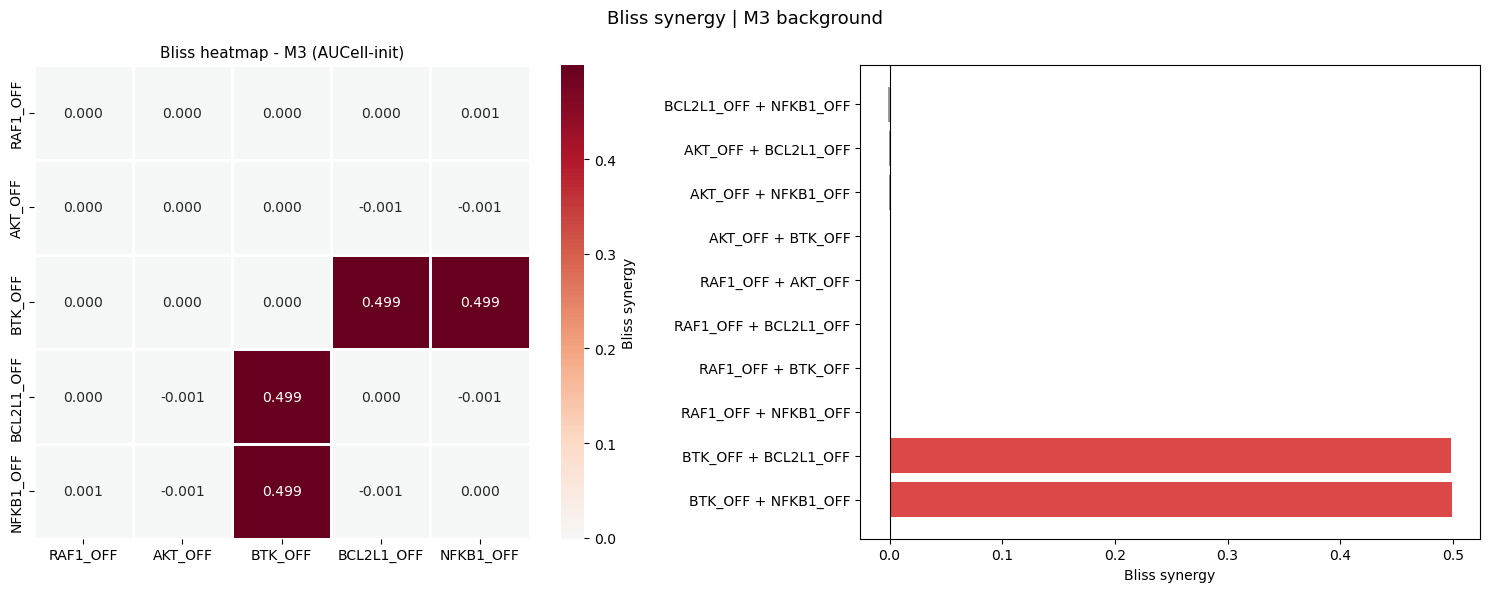

In [79]:
assert 'delta_Resistance' in screen_M3_df.columns and len(screen_M3_df)>0,     'Run S1b (Section 15) first'

selected_M3   = select_top_per_class(screen_M3_df, direction='OFF',
                                     score_col='delta_Resistance')
combo_nodes_M3 = list(selected_M3.values())
R_ref_M3      = REF_ATTRACTORS['M3']['Resistance']
single_R_M3   = {(r['node'],r['direction']): r['delta_Resistance']
                 for _, r in screen_M3_df.iterrows() if pd.notna(r['delta_Resistance'])}

print('Selected nodes (M3):')
for cls,(n,d) in selected_M3.items():
    print(f'  {cls:<15}: {n} {d}  ΔR={single_R_M3.get((n,d),0):+.3f}')

combo_M3_rows = []
for (nA,dA),(nB,dB) in combinations(combo_nodes_M3, 2):
    sim = build_sim_aucell('M3')
    try:
        sim.mutate(nA,dA); sim.mutate(nB,dB)
        final, _ = run_sim_static(sim)
        E_AB = final['Resistance'] - R_ref_M3
        E_A  = single_R_M3.get((nA,dA), 0)
        E_B  = single_R_M3.get((nB,dB), 0)
        B    = bliss_score(-E_A,-E_B,-E_AB)
        combo_M3_rows.append({
            'nodeA':f'{nA}_{dA}','nodeB':f'{nB}_{dB}',
            'combination':f'{nA}_{dA} + {nB}_{dB}',
            'E_A':E_A,'E_B':E_B,'E_AB':E_AB,'Bliss':B,
            **{k:final[k] for k in OUTPUT_NODES}
        })
        print(f'  {nA}_{dA} + {nB}_{dB}: Bliss={B:+.3f}')
    except Exception as e:
        print(f'  SKIP: {e}')

combo_M3_df = pd.DataFrame(combo_M3_rows)
if combo_M3_df.empty:
    print('WARNING: no combinations completed')
else:
    combo_M3_df = combo_M3_df.sort_values('Bliss', ascending=False)
    combo_M3_df.to_csv(f'{OUTPUT_DIR}/S3_bliss_M3.csv', index=False)
    ids = [f'{n}_{d}' for n,d in combo_nodes_M3]
    pivot = pd.DataFrame(0.0, index=ids, columns=ids)
    for _,r in combo_M3_df.iterrows():
        pivot.loc[r['nodeA'],r['nodeB']] = r['Bliss']
        pivot.loc[r['nodeB'],r['nodeA']] = r['Bliss']
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))
    sns.heatmap(pivot, annot=True, fmt='.3f', cmap='RdBu_r', center=0,
                ax=axes[0], linewidths=0.8, linecolor='white',
                cbar_kws={'label':'Bliss synergy'})
    axes[0].set_title('Bliss heatmap - M3 (AUCell-init)', fontsize=11)
    axes[1].barh(combo_M3_df['combination'], combo_M3_df['Bliss'],
                 color=['#d62728' if b>0.01 else '#1f77b4' if b<-0.01 else '#888888'
                        for b in combo_M3_df['Bliss']], alpha=0.85)
    axes[1].axvline(0, color='black', linewidth=0.8)
    axes[1].set_xlabel('Bliss synergy', fontsize=10)
    plt.suptitle('Bliss synergy | M3 background', fontsize=13)
    plt.tight_layout()
    plt.savefig(f'{OUTPUT_DIR}/S3_bliss_M3.pdf', dpi=300, bbox_inches='tight')
    plt.show()

---
## 18. S3b — Bliss synergy screen (M0 background, intrinsic resistance)

**Question:** Which pairs synergistically suppress the intrinsic resistance
programme present in AUCell-initialised M0 CLL cells?

Motivated by trajectory inference: M27 resistance reflects a pre-existing
programme already active at M0, not acquired from M3.

Screening 30 nodes × 2 directions (M0 AUCell-init)...
M0 screen complete.
  SOS1_OFF + AKT_OFF: Bliss=+0.000
  SOS1_OFF + BTK_OFF: Bliss=+0.000
  SOS1_OFF + BCL2L1_OFF: Bliss=+0.000
  SOS1_OFF + NFKB1_OFF: Bliss=+0.000
  AKT_OFF + BTK_OFF: Bliss=+0.000
  AKT_OFF + BCL2L1_OFF: Bliss=-0.000
  AKT_OFF + NFKB1_OFF: Bliss=-0.000
  BTK_OFF + BCL2L1_OFF: Bliss=+0.500
  BTK_OFF + NFKB1_OFF: Bliss=+0.500
  BCL2L1_OFF + NFKB1_OFF: Bliss=-0.000


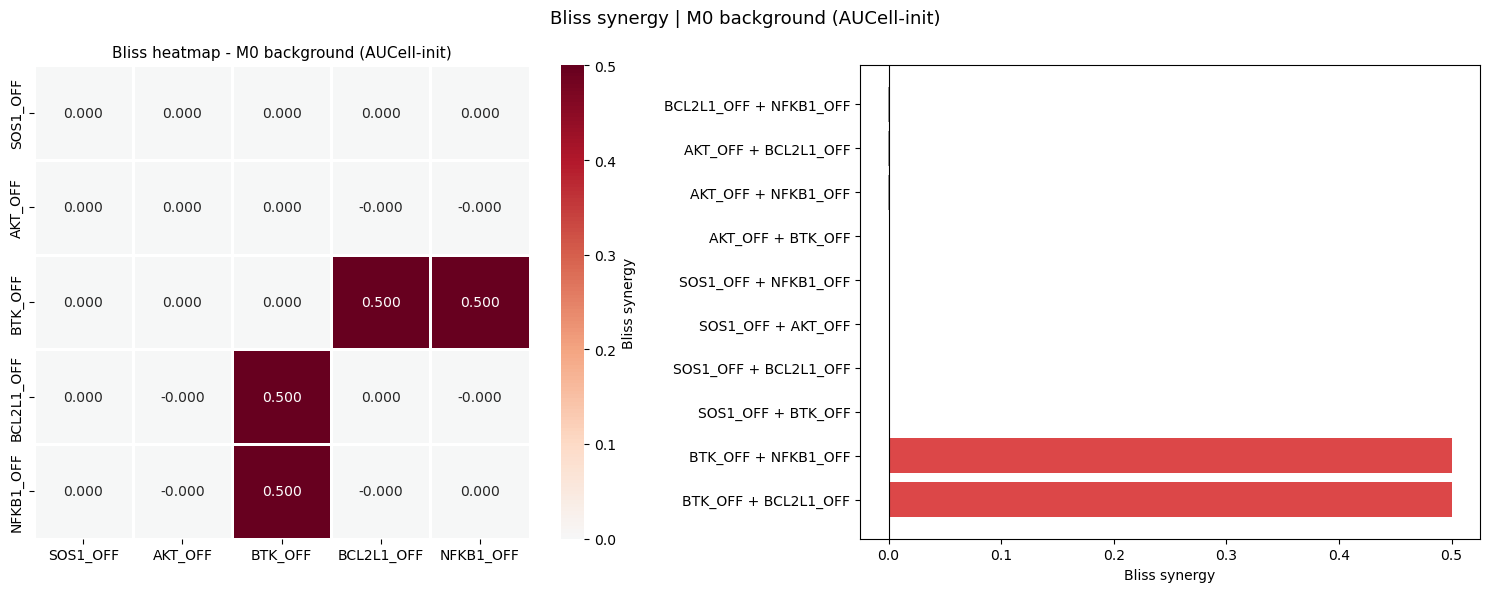

In [75]:
screen_M0_rows = []
print(f'Screening {len(screen_nodes)} nodes × 2 directions (M0 AUCell-init)...')
for node in screen_nodes:
    for direction in ['OFF','ON']:
        sim = build_sim_aucell('M0')
        try:
            sim.mutate(node, direction)
            final, _ = run_sim_static(sim)
            screen_M0_rows.append({
                'node':node,'direction':direction,'perturbation':f'{node}_{direction}',
                'delta_Resistance': final['Resistance'] - REF_ATTRACTORS['M0']['Resistance'],
                'delta_Apoptosis':  final['Apoptosis']  - REF_ATTRACTORS['M0']['Apoptosis'],
                **{k:final[k] for k in OUTPUT_NODES}
            })
        except Exception as e:
            print(f'  SKIP {node} {direction}: {e}')

screen_M0_df = pd.DataFrame(screen_M0_rows)
screen_M0_df.to_csv(f'{OUTPUT_DIR}/S3b_screen_M0.csv', index=False)
print('M0 screen complete.')

selected_M0   = select_top_per_class(screen_M0_df, direction='OFF',
                                     score_col='delta_Resistance')
combo_nodes_M0 = list(selected_M0.values())
R_ref_M0      = REF_ATTRACTORS['M0']['Resistance']
single_R_M0   = {(r['node'],r['direction']): r['delta_Resistance']
                 for _, r in screen_M0_df.iterrows() if pd.notna(r['delta_Resistance'])}

combo_M0_rows = []
for (nA,dA),(nB,dB) in combinations(combo_nodes_M0, 2):
    sim = build_sim_aucell('M0')
    try:
        sim.mutate(nA,dA); sim.mutate(nB,dB)
        final, _ = run_sim_static(sim)
        E_AB = final['Resistance'] - R_ref_M0
        E_A  = single_R_M0.get((nA,dA), 0)
        E_B  = single_R_M0.get((nB,dB), 0)
        B    = bliss_score(-E_A,-E_B,-E_AB)
        combo_M0_rows.append({
            'nodeA':f'{nA}_{dA}','nodeB':f'{nB}_{dB}',
            'combination':f'{nA}_{dA} + {nB}_{dB}',
            'E_A':E_A,'E_B':E_B,'E_AB':E_AB,'Bliss':B,
            **{k:final[k] for k in OUTPUT_NODES}
        })
        print(f'  {nA}_{dA} + {nB}_{dB}: Bliss={B:+.3f}')
    except Exception as e:
        print(f'  SKIP: {e}')

combo_M0_df = pd.DataFrame(combo_M0_rows)
if combo_M0_df.empty:
    print('WARNING: no combinations completed')
else:
    combo_M0_df = combo_M0_df.sort_values('Bliss', ascending=False)
    combo_M0_df.to_csv(f'{OUTPUT_DIR}/S3b_bliss_M0.csv', index=False)
    ids = [f'{n}_{d}' for n,d in combo_nodes_M0]
    pivot = pd.DataFrame(0.0, index=ids, columns=ids)
    for _,r in combo_M0_df.iterrows():
        pivot.loc[r['nodeA'],r['nodeB']] = r['Bliss']
        pivot.loc[r['nodeB'],r['nodeA']] = r['Bliss']
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))
    sns.heatmap(pivot, annot=True, fmt='.3f', cmap='RdBu_r', center=0,
                ax=axes[0], linewidths=0.8, linecolor='white',
                cbar_kws={'label':'Bliss synergy'})
    axes[0].set_title('Bliss heatmap - M0 background (AUCell-init)', fontsize=11)
    axes[1].barh(combo_M0_df['combination'], combo_M0_df['Bliss'],
                 color=['#d62728' if b>0.01 else '#1f77b4' if b<-0.01 else '#888888'
                        for b in combo_M0_df['Bliss']], alpha=0.85)
    axes[1].axvline(0, color='black', linewidth=0.8)
    axes[1].set_xlabel('Bliss synergy', fontsize=10)
    plt.suptitle('Bliss synergy | M0 background (AUCell-init)', fontsize=13)
    plt.tight_layout()
    plt.savefig(f'{OUTPUT_DIR}/S3b_bliss_M0.pdf', dpi=300, bbox_inches='tight')
    plt.show()

---
## 19. S4 — Basin of attraction mapping: M3 → M27

**Question:** What is the minimum combination of resistance events needed to
shift the AUCell-initialised M3 attractor into the M27 resistance basin?

  M3_baseline                    Apopt=0.500  Resist=0.500
  + BCL2/MCL1 ON                 Apopt=0.500  Resist=0.501
  + PTEN OFF                     Apopt=0.500  Resist=0.501
  + PLCG2_mutant ON              Apopt=0.001  Resist=1.000
  + BCL2 + PTEN                  Apopt=0.499  Resist=0.500
  + BCL2 + PLCG2_mut             Apopt=0.001  Resist=1.000
  + PTEN + PLCG2_mut             Apopt=0.000  Resist=1.000
  M27_full                       Apopt=0.000  Resist=1.000


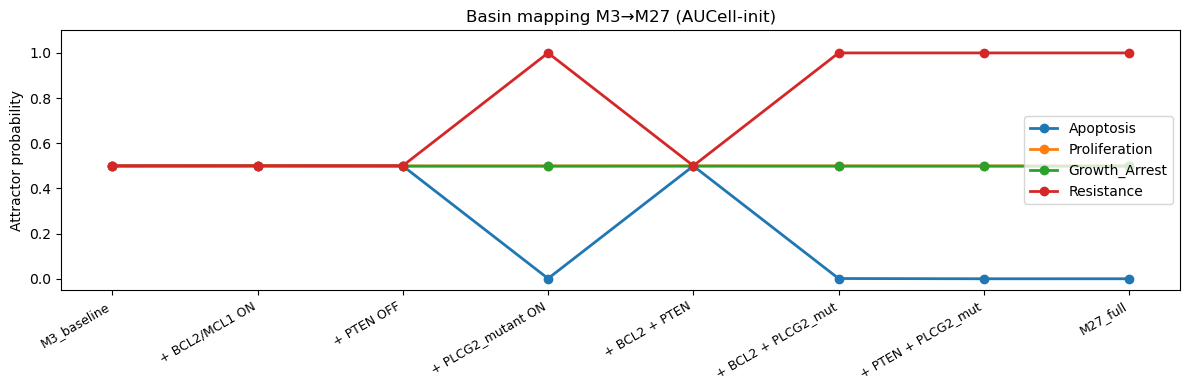

In [76]:
resistance_events = [
    ('M3_baseline',         []),
    ('+ BCL2/MCL1 ON',      [('BCL2','ON'),('MCL1','ON')]),
    ('+ PTEN OFF',          [('PTEN','OFF')]),
    ('+ PLCG2_mutant ON',   [('PLCG2_mutant','ON')]),
    ('+ BCL2 + PTEN',       [('BCL2','ON'),('MCL1','ON'),('PTEN','OFF')]),
    ('+ BCL2 + PLCG2_mut',  [('BCL2','ON'),('MCL1','ON'),('PLCG2_mutant','ON')]),
    ('+ PTEN + PLCG2_mut',  [('PTEN','OFF'),('PLCG2_mutant','ON')]),
    ('M27_full',            [('BCL2','ON'),('MCL1','ON'),
                             ('PTEN','OFF'),('PLCG2_mutant','ON')]),
]
basin_rows = []
for label, muts in resistance_events:
    sim = build_sim_aucell('M3')
    for node, direction in muts: sim.mutate(node, direction)
    final, _ = run_sim_static(sim)
    basin_rows.append({'condition':label, **final})
    print(f'  {label:<30} Apopt={final["Apoptosis"]:.3f}  Resist={final["Resistance"]:.3f}')

basin_df = pd.DataFrame(basin_rows).set_index('condition')
basin_df.to_csv(f'{OUTPUT_DIR}/S4_basin_mapping.csv')

fig, ax = plt.subplots(figsize=(12, 4))
x = range(len(basin_df))
for node, color in zip(OUTPUT_NODES,['#1f77b4','#ff7f0e','#2ca02c','#d62728']):
    ax.plot(x, basin_df[node], marker='o', color=color, linewidth=2, label=node)
ax.set_xticks(x); ax.set_xticklabels(basin_df.index, rotation=30, ha='right', fontsize=9)
ax.set_ylabel('Attractor probability'); ax.set_ylim(-0.05, 1.1)
ax.legend(loc='center right', fontsize=10)
ax.set_title('Basin mapping M3→M27 (AUCell-init)', fontsize=12)
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/S4_basin_mapping.pdf', dpi=300, bbox_inches='tight')
plt.show()

---
## 20. S5 — BTK dose-response

**Question:** How does the phenotypic attractor change across the full range of
BTK inhibition, and where does the patient's trough-derived operating point
sit on the dose-response curve?

BCL2 family nodes are left free so Apoptosis can respond dynamically to BTK.
The patient's mean inhibition (~65%) is marked as a vertical line.

  rate_up=0.00  (100% inhib)  Apopt=0.999  Resist=0.000  Prolif=0.000
  rate_up=0.10  ( 90% inhib)  Apopt=0.999  Resist=0.000  Prolif=0.000
  rate_up=0.20  ( 80% inhib)  Apopt=0.999  Resist=0.001  Prolif=0.000
  rate_up=0.30  ( 70% inhib)  Apopt=0.999  Resist=0.000  Prolif=0.000
  rate_up=0.40  ( 60% inhib)  Apopt=0.999  Resist=0.001  Prolif=0.000
  rate_up=0.50  ( 50% inhib)  Apopt=0.999  Resist=0.001  Prolif=0.000
  rate_up=0.60  ( 40% inhib)  Apopt=0.999  Resist=0.001  Prolif=0.000
  rate_up=0.70  ( 30% inhib)  Apopt=0.999  Resist=0.001  Prolif=0.000
  rate_up=0.80  ( 20% inhib)  Apopt=0.999  Resist=0.001  Prolif=0.000
  rate_up=0.90  ( 10% inhib)  Apopt=0.999  Resist=0.001  Prolif=0.000
  rate_up=1.00  (  0% inhib)  Apopt=0.999  Resist=0.001  Prolif=0.000


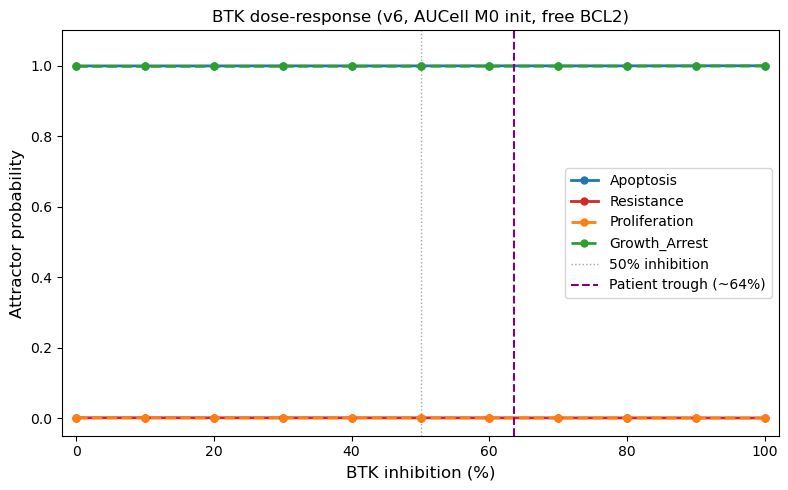

Patient operating point: ~64% BTK inhibition


In [77]:
# S5 — BTK inhibition dose-response (v6)
# BCL2 family left FREE so Apoptosis responds dynamically to BTK activity.
# IL3 locked OFF (only cytokine in v6; absent under ibrutinib treatment).
# AUCell M0 TF states seed the simulation (excluding BCL2 family and AUCELL_LOCKED).

btk_activities = np.linspace(0.0, 1.0, 11)
dose_rows = []

for btk_rate_up in btk_activities:
    sim = maboss.load(BND_FILE, CFG_BASE)
    maboss.set_output(sim, OUTPUT_NODES + RESISTANCE_INPUTS)
    sim.mutate('PLCG2_mutant', 'OFF')
    sim.mutate('IL3', 'OFF')
    # BCL2 family deliberately FREE — Apoptosis must respond to BTK

    # AUCell M0 TF states (exclude BCL2 family and locked nodes)
    if AUCELL_AVAILABLE:
        for node, val in aucell_istates['M0'].items():
            if node not in AUCELL_LOCKED and node not in {'BCL2', 'BCL2L1', 'MCL1'}:
                try: sim.network.set_istate(node, [1-float(val), float(val)])
                except Exception: pass

    sim.network.set_istate('BTK', [1, 0])   # start BTK OFF
    sim.network['BTK'].set_rate(str(round(btk_rate_up, 4)), '1.0')
    sim.param['max_time']     = MAX_TIME
    sim.param['time_tick']    = TIME_TICK
    sim.param['sample_count'] = SAMPLE_COUNT
    sim.param['thread_count'] = N_THREADS

    final, _ = run_sim(sim)
    inh = round((1 - btk_rate_up) * 100)
    dose_rows.append({'BTK_rate_up': btk_rate_up,
                      'BTK_inhibition_pct': inh, **final})
    print(f'  rate_up={btk_rate_up:.2f}  ({inh:3d}% inhib)  '
          f'Apopt={final["Apoptosis"]:.3f}  Resist={final["Resistance"]:.3f}  '
          f'Prolif={final["Proliferation"]:.3f}')

dose_df = pd.DataFrame(dose_rows)
dose_df.to_csv(f'{OUTPUT_DIR}/S5_BTK_dose_response.csv', index=False)

patient_inh = monthly_stats.loc[monthly_stats['month'] > 0, 'inhibition'].mean() * 100

fig, ax = plt.subplots(figsize=(8, 5))
for node, color, ls in [
    ('Apoptosis',    '#1f77b4', '-'),
    ('Resistance',   '#d62728', '-'),
    ('Proliferation','#ff7f0e', '--'),
    ('Growth_Arrest','#2ca02c', '--'),
]:
    ax.plot(dose_df['BTK_inhibition_pct'], dose_df[node],
            color=color, linestyle=ls, linewidth=2,
            marker='o', markersize=5, label=node)

ax.axvline(50, color='gray', linestyle=':', linewidth=1, alpha=0.7,
           label='50% inhibition')
ax.axvline(patient_inh, color='purple', linestyle='--', linewidth=1.5,
           label=f'Patient trough (~{patient_inh:.0f}%)')
ax.set_xlabel('BTK inhibition (%)', fontsize=12)
ax.set_ylabel('Attractor probability', fontsize=12)
ax.set_ylim(-0.05, 1.1); ax.set_xlim(-2, 102)
ax.legend(loc='center right', fontsize=10)
ax.set_title('BTK dose-response (v6, AUCell M0 init, free BCL2)', fontsize=12)
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/S5_BTK_dose_response.pdf', dpi=300, bbox_inches='tight')
plt.show()
print(f'Patient operating point: ~{patient_inh:.0f}% BTK inhibition')